# Proyecto final · Minería de Datos 1
## Dataset 1: Calificaciones de estudiantes (Student Grade SES)
### 03. EDA – Análisis visual

**Fuente de datos:** `data/processed/calificaciones_limpio.csv`

**Introducción**

El análisis exploratorio visual complementa el análisis estadístico mediante histogramas, diagramas de caja, gráficos de categorías, dispersión y mapas de calor. Su finalidad es examinar la distribución de las calificaciones y describir patrones asociados con las características académicas, familiares, socioeconómicas y escolares de los estudiantes.

**Objetivos**

- Visualizar la distribución de las variables y del rendimiento académico.
- Examinar diferencias entre grupos y asociaciones entre variables, sin atribuir causalidad.
- Identificar valores atípicos y relaciones que deban considerarse durante el preprocesamiento para K-Means.
- Sintetizar los principales hallazgos visuales y establecer conclusiones sustentadas en los resultados.

**Criterios metodológicos**

El análisis es descriptivo y no modifica el CSV. Los valores imputados durante el ETL se conservan y sus limitaciones se consideran al interpretar los gráficos. Las categorías de calificación y riesgo pueden derivarse de la nota final, por lo que no se interpretarán como factores independientes de ella. Los valores atípicos se examinarán, **pero cualquier decisión de transformación o tratamiento para K-Means hay que verlo en el preprocesamiento**

## Parte 03. EDA – Análisis visual

### 1. Importación de librerías

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.2f}".format)
print("Pandas:", pd.__version__, "| NumPy:", np.__version__)

Pandas: 3.1.1 | NumPy: 2.5.4


### 2. Carga del dataset limpio

Se emplea la misma versión procesada utilizada en `02_EDA_Estadistico.ipynb`. Se conservan sus columnas y valores; los nombres internos permiten compartir criterios entre ambos análisis.

In [2]:
archivo = "calificaciones_limpio.csv"
actual = Path.cwd().resolve()
raiz = next((p for p in [actual, *actual.parents] if (p / "data" / "processed").is_dir()), None)
ruta_windows = Path(r"C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2026\MineriaDatos\Proyecto\Mineria_Datos_1\data\processed\calificaciones_limpio.csv")
rutas = ([raiz / "data" / "processed" / archivo] if raiz else []) + [ruta_windows]
ruta_csv = next((p for p in rutas if p.is_file()), None)
if ruta_csv is None:
    raise FileNotFoundError(f"No se encontró {archivo}. Rutas revisadas: {[str(p) for p in rutas]}")

df = pd.read_csv(ruta_csv, encoding="utf-8-sig", low_memory=False)

# Orden de las 29 variables según el notebook 02 y el ETL del Dataset 1.
columnas_originales = [
    "student_id", "academic_year", "survey_date", "age", "gender",
    "grade_level", "school_type", "residence_type", "family_size", "num_siblings",
    "single_parent_household", "family_income_bracket", "annual_family_income_inr",
    "father_education_level", "mother_education_level", "father_occupation", "mother_occupation",
    "has_internet_access", "has_computer_or_laptop", "distance_to_school_km",
    "scholarship_status", "extra_tutoring", "parental_involvement_score",
    "study_hours_per_week", "attendance_rate_pct", "previous_year_grade_pct",
    "final_grade_pct", "grade_class", "at_risk_flag"
]

if set(columnas_originales).issubset(df.columns):
    mapa_columnas = {c: c for c in columnas_originales}
elif df.shape[1] == len(columnas_originales):
    mapa_columnas = dict(zip(df.columns.tolist(), columnas_originales))
    print("Equivalencias basadas en el orden original; se muestran para verificación:")
    display(pd.DataFrame({"Columna del CSV": list(mapa_columnas),
                          "Nombre interno": list(mapa_columnas.values())}))
else:
    raise ValueError("Se esperan 29 columnas del dataset limpio. Revisá el archivo seleccionado.")
base = df.rename(columns=mapa_columnas).copy()
print("Archivo:", ruta_csv)
print("Dimensiones:", base.shape)

Equivalencias basadas en el orden original; se muestran para verificación:


,Columna del CSV,Nombre interno
0,id_estudiante,student_id
1,periodo_academico,academic_year
2,fecha_encuesta,survey_date
3,edad,age
4,genero,gender
5,nivel_academico,grade_level
6,tipo_escuela,school_type
7,zona_residencia,residence_type
8,tamano_familia,family_size
9,numero_hermanos,num_siblings


Archivo: C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2026\MineriaDatos\Proyecto\Mineria_Datos_1\data\processed\calificaciones_limpio.csv
Dimensiones: (12000, 29)


### 3. Verificación de dimensiones y estructura

In [3]:
verificacion = pd.DataFrame({
    "Indicador": ["Registros", "Variables", "Valores nulos", "Filas duplicadas", "Identificadores duplicados"],
    "Resultado": [len(base), base.shape[1], int(base.isna().sum().sum()),
                  int(base.duplicated().sum()), int(base["student_id"].duplicated().sum())]
})
display(verificacion)
if base.empty:
    raise ValueError("El archivo está vacío y no es posible realizar el análisis visual.")
if base["student_id"].duplicated().any():
    print("Observación: revisar identificadores repetidos antes del análisis.")

,Indicador,Resultado
0,Registros,12000
1,Variables,29
2,Valores nulos,0
3,Filas duplicadas,0
4,Identificadores duplicados,0


### 4. Clasificación de variables para el análisis visual

In [4]:
etiquetas = {
    "student_id":"Identificador del estudiante", "academic_year":"Año académico",
    "survey_date":"Fecha de encuesta", "age":"Edad", "gender":"Género",
    "grade_level":"Grado académico", "school_type":"Tipo de centro educativo",
    "residence_type":"Zona de residencia", "family_size":"Tamaño familiar",
    "num_siblings":"Número de hermanos", "single_parent_household":"Hogar monoparental",
    "family_income_bracket":"Categoría de ingreso familiar",
    "annual_family_income_inr":"Ingreso familiar anual (INR)",
    "father_education_level":"Educación del padre", "mother_education_level":"Educación de la madre",
    "father_occupation":"Ocupación del padre", "mother_occupation":"Ocupación de la madre",
    "has_internet_access":"Acceso a internet", "has_computer_or_laptop":"Tiene computadora",
    "distance_to_school_km":"Distancia a la escuela (km)", "scholarship_status":"Estado de beca",
    "extra_tutoring":"Tutorías adicionales", "parental_involvement_score":"Participación parental",
    "study_hours_per_week":"Horas de estudio semanales", "attendance_rate_pct":"Asistencia (%)",
    "previous_year_grade_pct":"Calificación anterior (%)", "final_grade_pct":"Calificación final (%)",
    "grade_class":"Categoría de calificación", "at_risk_flag":"Indicador de riesgo académico"
}

numericas = [
    "age", "family_size", "num_siblings", "annual_family_income_inr",
    "distance_to_school_km", "parental_involvement_score", "study_hours_per_week",
    "attendance_rate_pct", "previous_year_grade_pct", "final_grade_pct"
]
categoricas = [
    "academic_year", "gender", "grade_level", "school_type", "residence_type",
    "single_parent_household", "family_income_bracket", "father_education_level",
    "mother_education_level", "father_occupation", "mother_occupation",
    "has_internet_access", "has_computer_or_laptop", "scholarship_status",
    "extra_tutoring", "grade_class", "at_risk_flag"
]
objetivo = "final_grade_pct"
variables_derivadas_objetivo = ["grade_class", "at_risk_flag"]
for col in numericas:
    base[col] = pd.to_numeric(base[col], errors="coerce")

resumen_tipos = pd.DataFrame({
    "Tipo de análisis": ["Numéricas", "Categóricas", "Identificador", "Fecha"],
    "Cantidad": [len(numericas), len(categoricas), 1, 1],
    "Uso": ["Distribuciones y relaciones", "Frecuencias y grupos", "No se grafica", "No se utiliza como escala continua"]
})
display(resumen_tipos)

,Tipo de análisis,Cantidad,Uso
0,Numéricas,10,Distribuciones y relaciones
1,Categóricas,17,Frecuencias y grupos
2,Identificador,1,No se grafica
3,Fecha,1,No se utiliza como escala continua


### 5. Configuración y estilo de las visualizaciones

Se emplean ejes y unidades explícitas, paleta consistente y tamaños adecuados para facilitar la lectura de los gráficos.

In [5]:
sns.set_theme(style="whitegrid", context="notebook", font_scale=0.93)
AZUL = "#1E376C"
AZUL_CLARO = "#567DB6"
TURQUESA = "#1D8B8F"
ROJO = "#C94D43"
GRIS = "#4D5967"
PALETA = [AZUL, TURQUESA, AZUL_CLARO, "#8B78A9", "#BD8747", "#628B69"]
plt.rcParams.update({
    "figure.dpi": 115, "savefig.dpi": 180,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "semibold", "axes.titlesize": 11,
    "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "figure.facecolor": "white", "axes.facecolor": "white",
})

def interpretar(texto):
    display(Markdown("**Interpretación:** " + texto))

def texto_categoria(v):
    s = str(v)
    if s.lower() == "desconocido": return "Desconocido"
    return s

def tabla_grupos(variable, min_n=30):
    """Medias descriptivas de grupos con tamaño verificable."""
    s = base[variable].astype("string").fillna("Desconocido")
    tabla = (pd.DataFrame({"Grupo": s, "Nota": base[objetivo]})
             .groupby("Grupo", dropna=False)["Nota"]
             .agg(n="count", media="mean", mediana="median").reset_index())
    tabla["Grupo"] = tabla["Grupo"].astype(str)
    return tabla.loc[tabla["n"] >= min_n].sort_values("media", ascending=False)

def grafico_medias(variable, ax, min_n=30, max_categorias=9):
    tabla = tabla_grupos(variable, min_n).head(max_categorias)
    if tabla.empty:
        ax.text(.5,.5, "Sin grupos con muestra suficiente", transform=ax.transAxes,
                ha="center", va="center")
        ax.set_axis_off()
        return tabla
    tabla = tabla.sort_values("media")
    y = np.arange(len(tabla))
    ax.barh(y, tabla["media"], color=AZUL_CLARO, height=.68)
    ax.set_yticks(y, tabla["Grupo"].astype(str))
    ax.set_xlabel("Calificación final promedio (%)")
    ax.set_title(etiquetas[variable])
    ax.set_xlim(0, min(103, max(80, tabla["media"].max() + 10)))
    for iy, val, n in zip(y, tabla["media"], tabla["n"]):
        ax.text(val + 1, iy, f"{val:.1f} (n={n})", va="center", fontsize=7)
    return tabla

def interpretacion_grupos(variable, minimo=30):
    t = tabla_grupos(variable, minimo)
    if len(t) >= 2:
        mayor, menor = t.iloc[0], t.iloc[-1]
        interpretar(f"Para **{etiquetas[variable].lower()}**, las medias van de "
                   f"**{menor['media']:.2f} %** ({menor['Grupo']}, n={menor['n']}) a "
                   f"**{mayor['media']:.2f} %** ({mayor['Grupo']}, n={mayor['n']}). "
                   "Es una diferencia descriptiva, no causal; se muestran grupos con al menos 30 estudiantes.")
    else:
        interpretar("No hay suficientes grupos comparables con al menos 30 estudiantes.")

### 6. Distribución de las variables numéricas (histogramas)

Los histogramas permiten visualizar concentración, dispersión y asimetría. Se usan las escalas originales para interpretar sus unidades.

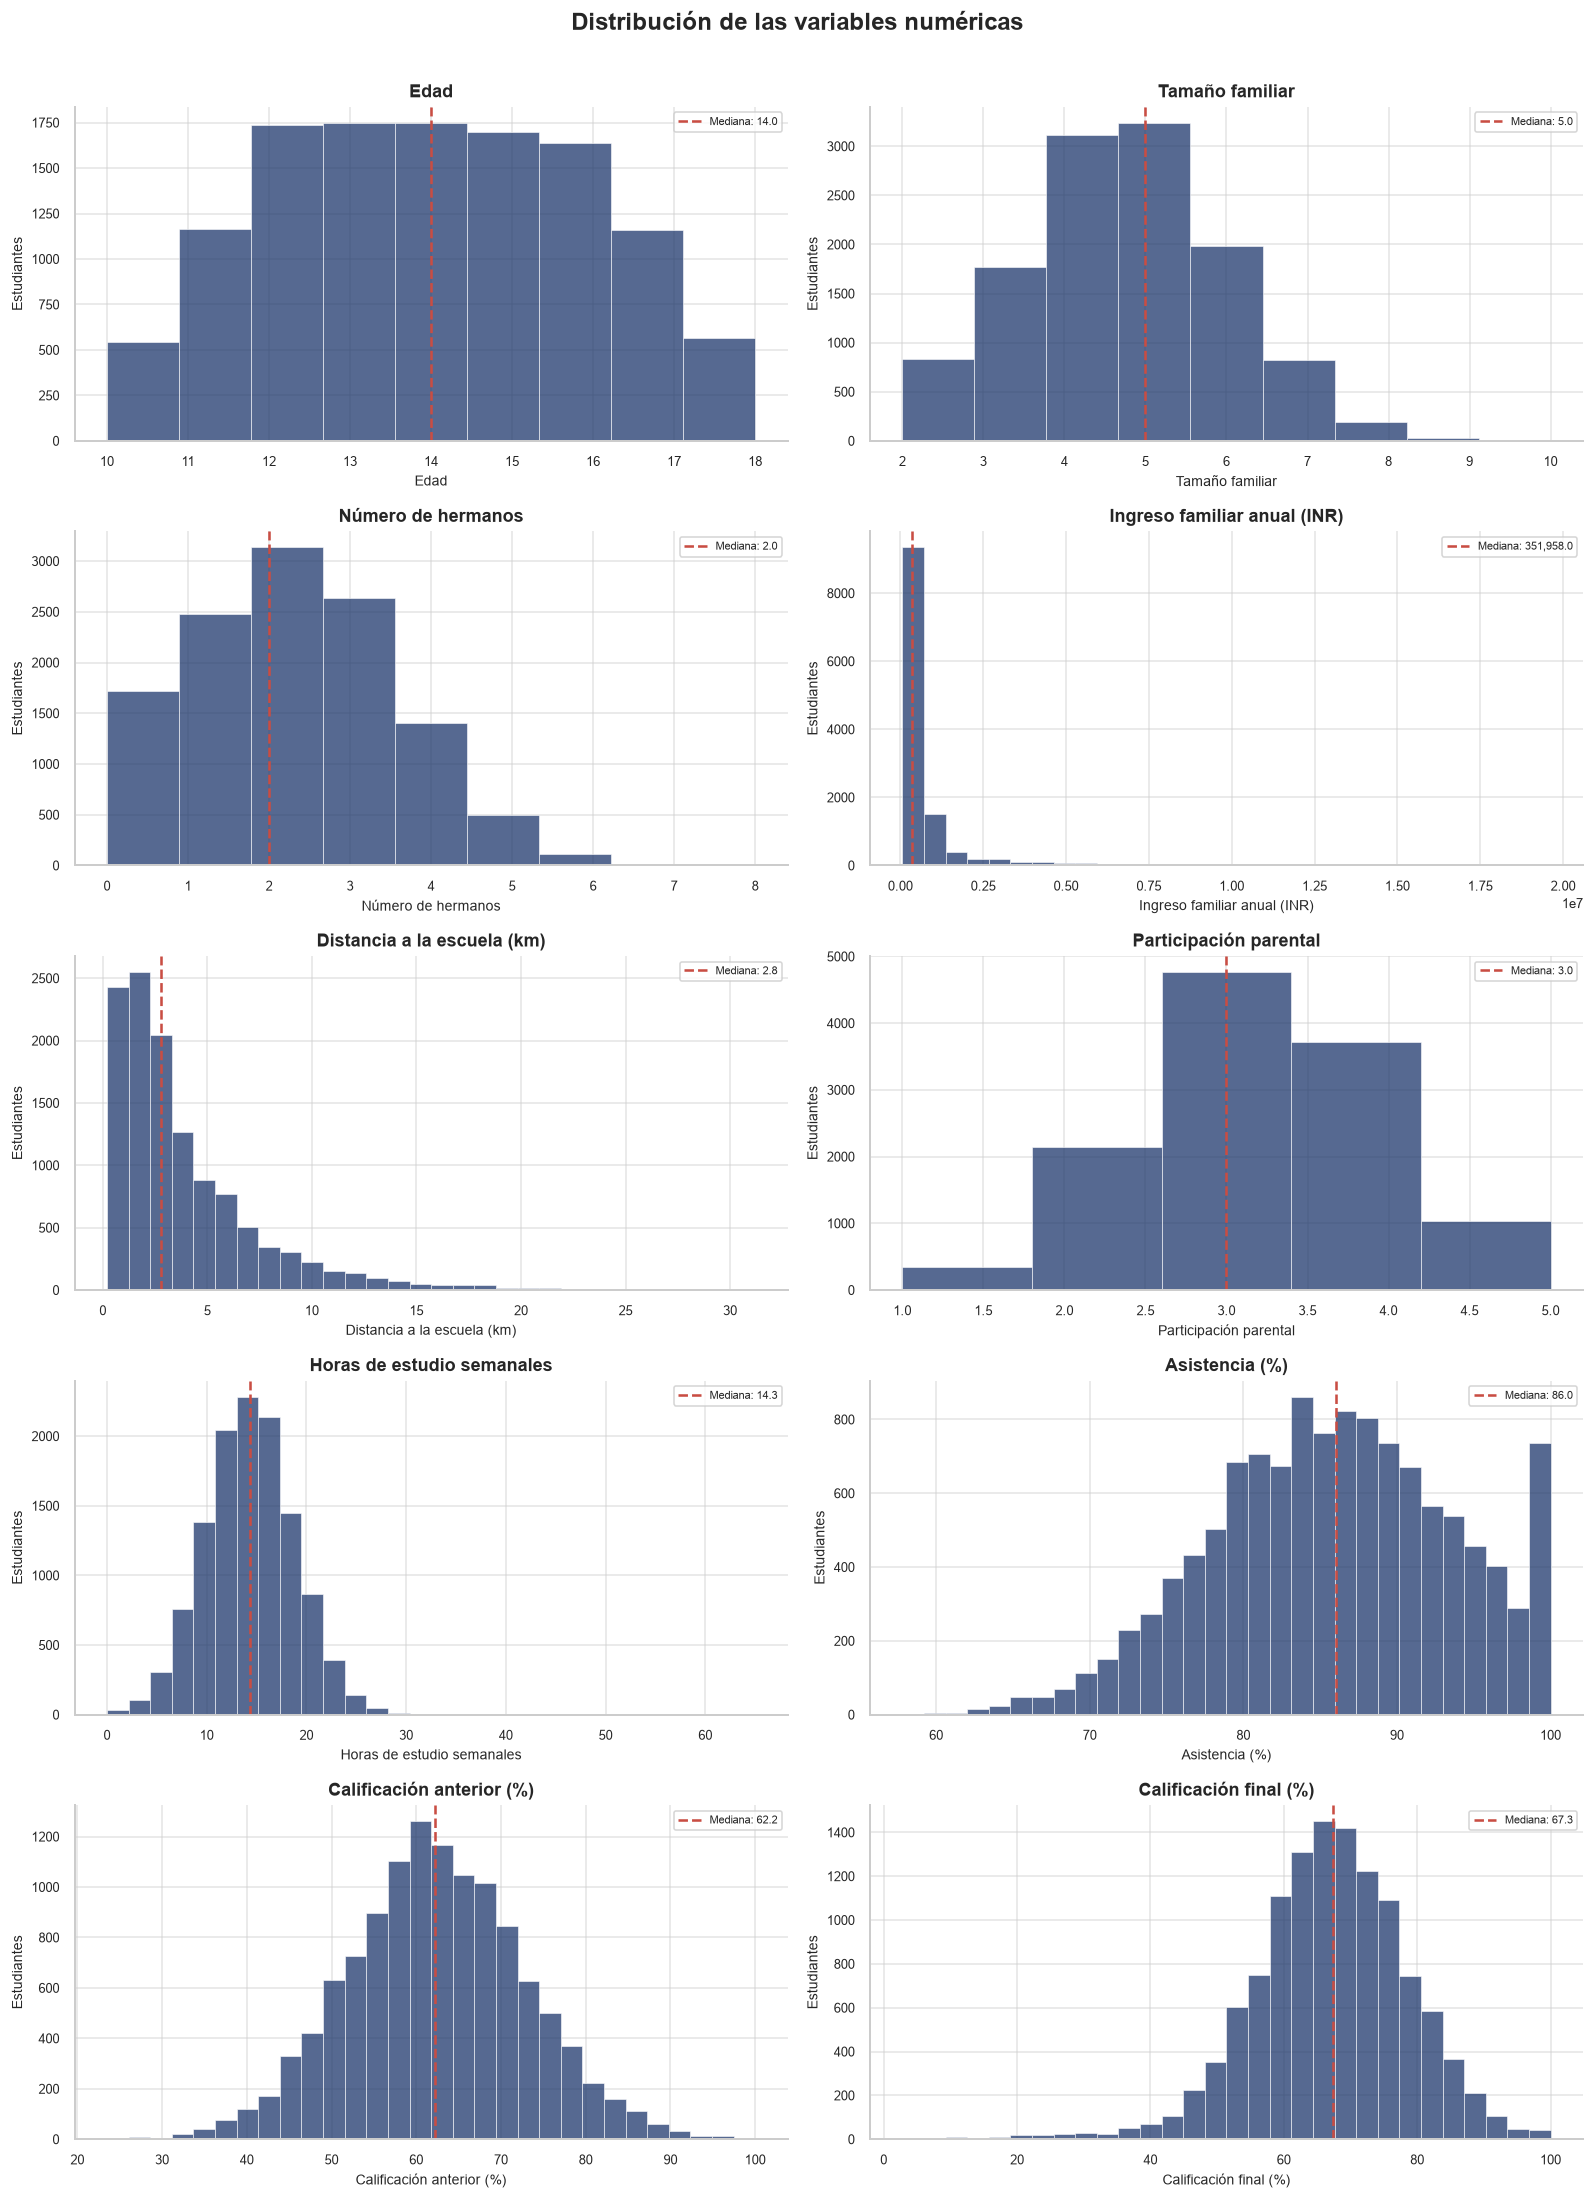

In [30]:
fig, ejes = plt.subplots(5, 2, figsize=(14, 19))
for ax, col in zip(ejes.flat, numericas):
    datos = base[col].dropna()
    sns.histplot(datos, bins=30 if datos.nunique() > 30 else min(15, max(3, datos.nunique())),
                 ax=ax, color=AZUL, edgecolor="white", linewidth=.35)
    if not datos.empty:
        ax.axvline(datos.median(), color=ROJO, linestyle="--", linewidth=1.6,
                   label=f"Mediana: {datos.median():,.1f}")
    ax.set(title=etiquetas[col], xlabel=etiquetas[col], ylabel="Estudiantes")
    ax.legend(fontsize=7, loc="upper right")
fig.suptitle("Distribución de las variables numéricas", fontsize=15, weight="bold", y=1.005)
plt.tight_layout()
plt.show()


**Interpretación de resultados:**

1. **Distribución de las variables:** los histogramas muestran diferentes comportamientos en las características académicas, familiares y socioeconómicas. Algunas variables concentran sus valores alrededor de la mediana, mientras que otras presentan distribuciones asimétricas.

2. **Ingresos familiares:** presentan una distribución asimétrica, con diferencias importantes entre los niveles económicos de los estudiantes y presencia de valores elevados.

3. **Hábitos académicos:** las horas de estudio, la asistencia y las calificaciones muestran concentraciones de valores en determinados intervalos, aunque también existen estudiantes con comportamientos alejados de los más frecuentes.

4. **Características familiares:** variables como el tamaño familiar y el número de hermanos presentan distribuciones concentradas en determinados valores, con algunos registros menos frecuentes.

5. **Valores atípicos:** algunas distribuciones presentan valores extremos que podrían representar características reales de los estudiantes. Estos valores no deben eliminarse automáticamente.

6. **Consideraciones para K-Means:** las diferencias de escala, la asimetría y los valores extremos pueden influir en las distancias y los centroides. Durante el preprocesamiento será necesario evaluar transformaciones, métodos de escalado y posibles tratamientos de valores atípicos.

**Conclusión:** las variables numéricas presentan distribuciones diferentes, por lo que no sería adecuado aplicar automáticamente el mismo tratamiento a todas. Estas características deberán considerarse durante el preprocesamiento para K-Means.


### 7. Distribución de las variables categóricas (gráficos de barras)

Se muestran frecuencias de categorías académicas y socioeconómicas. La clase de calificación y el riesgo se consideran **indicadores descriptivos**, no causas del rendimiento.

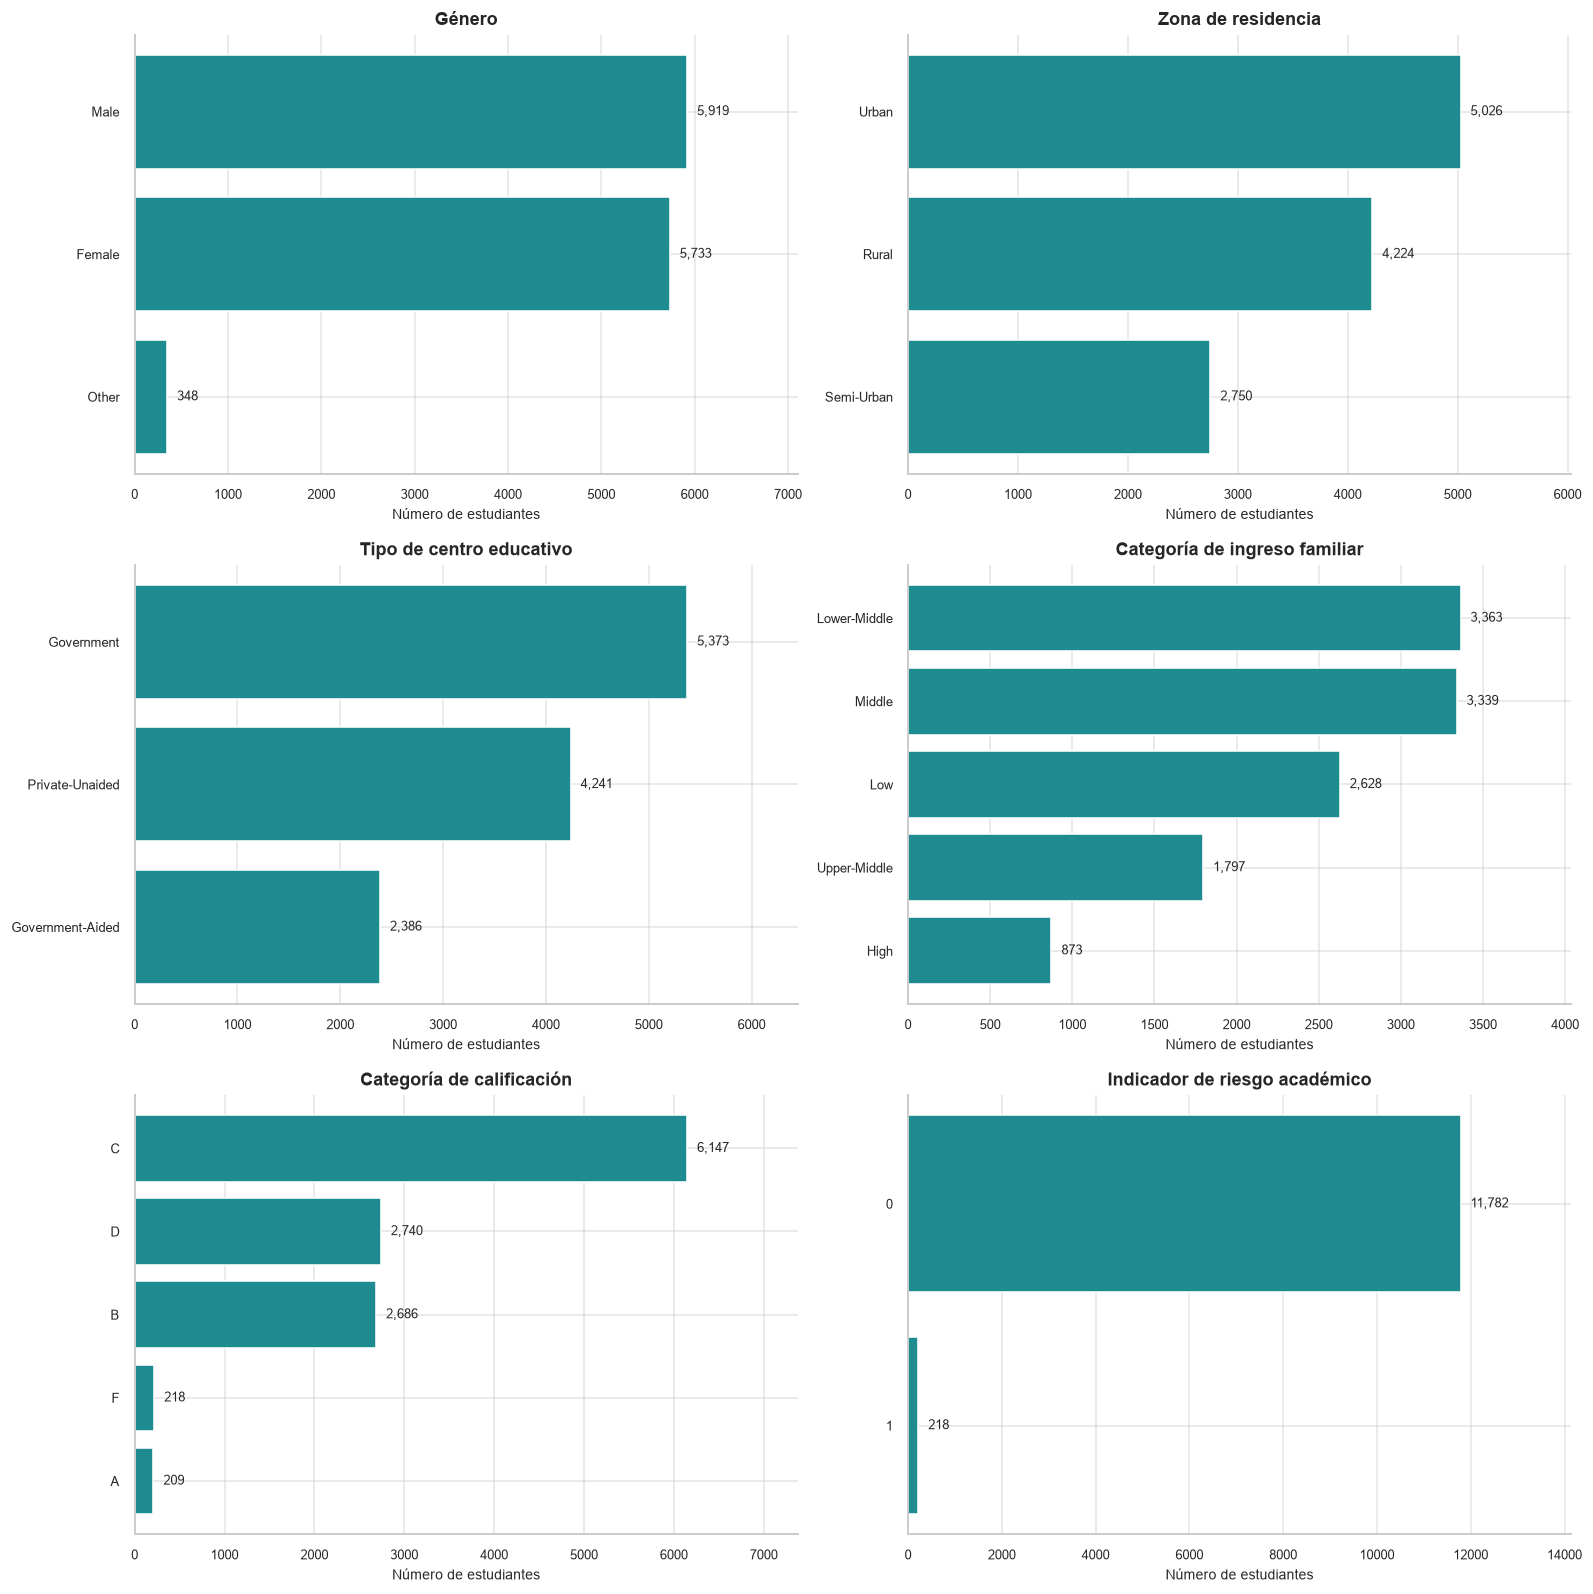

**Interpretación:** Predominan las siguientes categorías: Género: **Male** (49.3 %); Zona de residencia: **Urban** (41.9 %); Tipo de centro educativo: **Government** (44.8 %); Categoría de ingreso familiar: **Lower-Middle** (28.0 %); Categoría de calificación: **C** (51.2 %); Indicador de riesgo académico: **0** (98.2 %). La frecuencia de una categoría no demuestra relación con la nota final.

In [7]:
variables_barras = ["gender", "residence_type", "school_type",
                    "family_income_bracket", "grade_class", "at_risk_flag"]
fig, ejes = plt.subplots(3, 2, figsize=(14, 14))
for ax, col in zip(ejes.flat, variables_barras):
    frec = base[col].astype("string").fillna("Desconocido").value_counts().head(9)
    y = np.arange(len(frec))
    ax.barh(y, frec.values, color=TURQUESA)
    ax.set_yticks(y, frec.index.astype(str))
    ax.invert_yaxis()
    ax.set(title=etiquetas[col], xlabel="Número de estudiantes")
    limite = frec.max() * 1.20 if len(frec) else 1
    ax.set_xlim(0, limite)
    for j, valor in enumerate(frec.values):
        ax.text(valor + limite*.015, j, f"{valor:,}", va="center", fontsize=8)
plt.tight_layout()
plt.show()

resumen_categorias = []
for col in variables_barras:
    frec = base[col].astype("string").fillna("Desconocido").value_counts()
    if len(frec):
        resumen_categorias.append(f"{etiquetas[col]}: **{frec.index[0]}** ({100*frec.iloc[0]/len(base):.1f} %)")
interpretar("Predominan las siguientes categorías: " + "; ".join(resumen_categorias) +
           ". La frecuencia de una categoría no demuestra relación con la nota final.")

### 8. Análisis de valores atípicos (diagramas de caja)

Los diagramas de caja señalan observaciones fuera de los límites de 1,5 veces el rango intercuartílico (IQR). **Un valor atípico no es necesariamente un error**. No se elimina ningún registro en esta etapa.

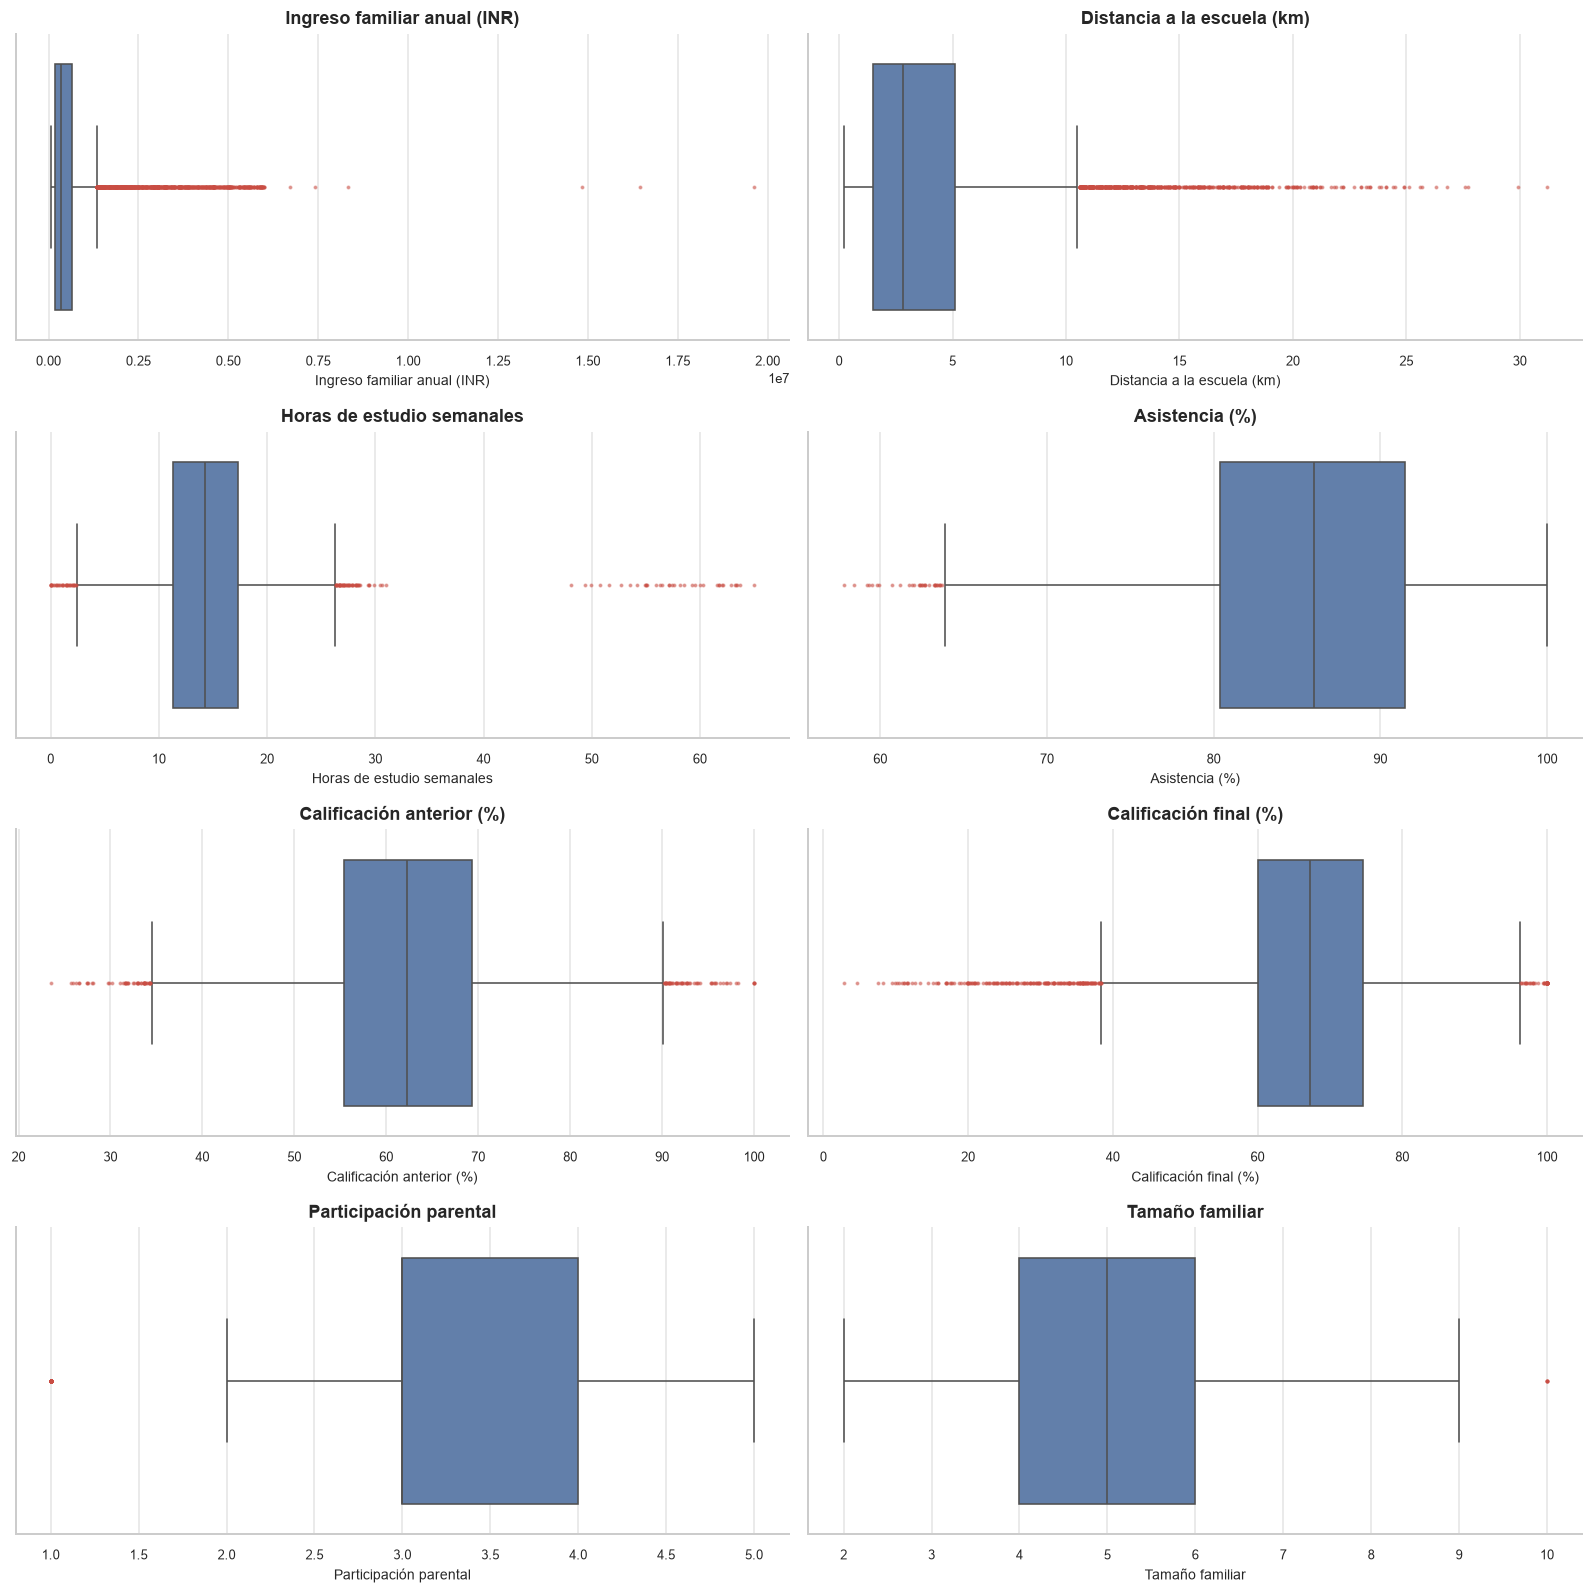

In [31]:
variables_atipicos = ["annual_family_income_inr", "distance_to_school_km",
                      "study_hours_per_week", "attendance_rate_pct",
                      "previous_year_grade_pct", "final_grade_pct",
                      "parental_involvement_score", "family_size"]
fig, ejes = plt.subplots(4, 2, figsize=(14, 14))
for ax, col in zip(ejes.flat, variables_atipicos):
    sns.boxplot(x=base[col].dropna(), ax=ax, color=AZUL_CLARO,
                flierprops={"marker":".", "markersize":3, "markerfacecolor":ROJO,
                            "markeredgecolor":ROJO, "alpha":.45})
    ax.set(title=etiquetas[col], xlabel=etiquetas[col])
plt.tight_layout()
plt.show()


**Interpretación de resultados:**

1. **Identificación de valores atípicos:** los diagramas de caja y el método IQR permiten identificar observaciones alejadas de la distribución central de cada variable, utilizando como referencia 1,5 veces el rango intercuartílico.

2. **Ingresos familiares:** se observan diferencias importantes en los niveles económicos, con valores elevados que pueden influir en los cálculos estadísticos y en las distancias entre estudiantes.

3. **Distancia escolar y horas de estudio:** los valores extremos representan casos de estudiantes con distancias o tiempos de estudio diferentes a los habituales. Estos registros no necesariamente son errores.

4. **Asistencia y calificaciones:** los valores alejados de las concentraciones principales pueden representar estudiantes con niveles de asistencia o rendimiento académico poco frecuentes, por lo que deben conservarse mientras no existan evidencias de inconsistencias.

5. **Características familiares:** los valores extremos en el tamaño familiar y la participación parental deben interpretarse considerando la naturaleza y los rangos válidos de cada variable.

6. **Consideraciones para K-Means:** los valores atípicos pueden afectar el cálculo de distancias y desplazar los centroides, especialmente en variables con escalas amplias. Durante el preprocesamiento será necesario comparar técnicas de escalado, posibles transformaciones y tratamientos de valores extremos, justificando cualquier modificación.

**Conclusión:** los valores atípicos identificados mediante IQR no deben eliminarse automáticamente, ya que pueden representar diferencias reales entre los estudiantes. Se recomienda conservarlos durante el EDA y evaluar su influencia antes de aplicar K-Means.


### 9. Distribución del rendimiento académico

Se examina con más detalle la forma de la calificación final, su dispersión central y la proporción por categoría de calificación.

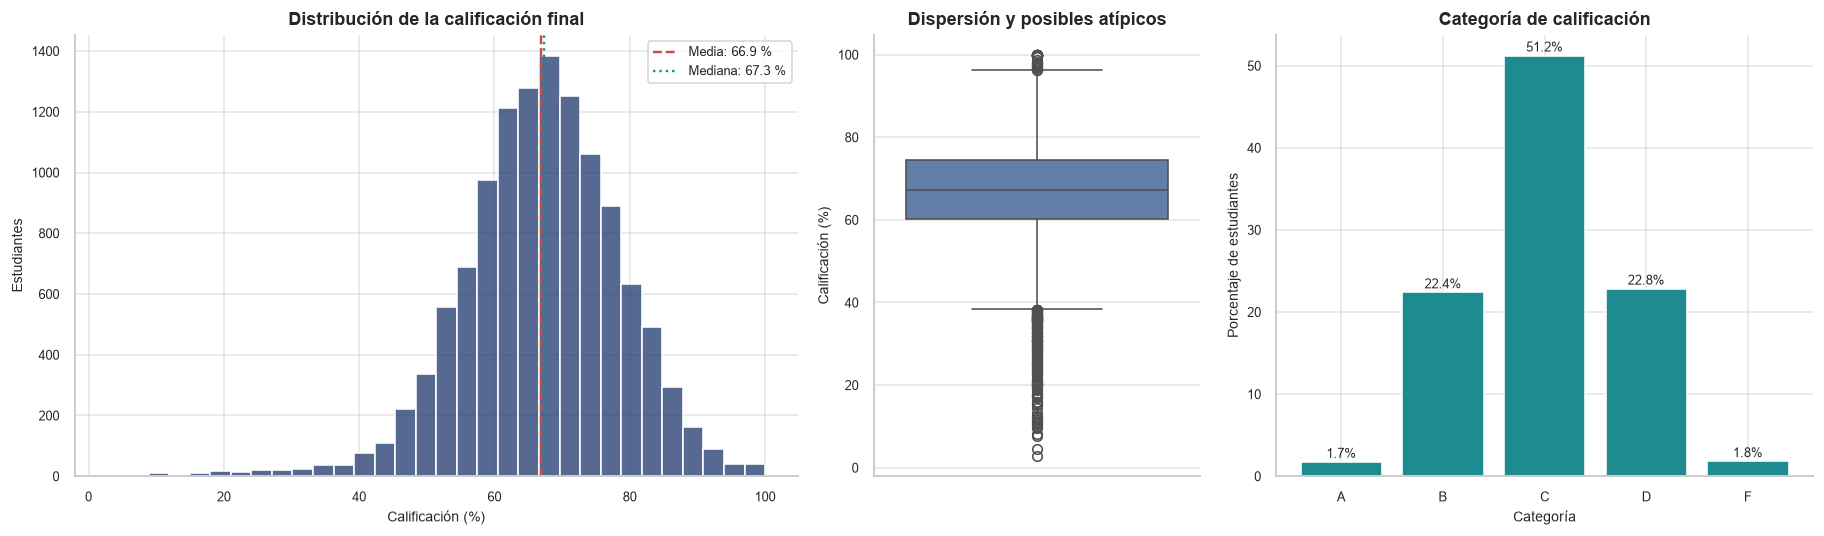

**Interpretación:** La calificación final tiene media **66.94 %**, mediana **67.30 %** y el 50 % central se sitúa entre **60.10 %** y **74.60 %**. Las categorías de nota describen el resultado, pero no deben emplearse como factores independientes de él.

In [9]:
notas = base[objetivo].dropna()
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"width_ratios":[1.55,.7,1.15]})
sns.histplot(notas, bins=32, color=AZUL, ax=ejes[0], edgecolor="white")
ejes[0].axvline(notas.mean(), color=ROJO, linestyle="--", label=f"Media: {notas.mean():.1f} %")
ejes[0].axvline(notas.median(), color=TURQUESA, linestyle=":", label=f"Mediana: {notas.median():.1f} %")
ejes[0].set(title="Distribución de la calificación final", xlabel="Calificación (%)", ylabel="Estudiantes")
ejes[0].legend(fontsize=8)
sns.boxplot(y=notas, ax=ejes[1], color=AZUL_CLARO)
ejes[1].set(title="Dispersión y posibles atípicos", ylabel="Calificación (%)")
frec = base["grade_class"].astype(str).value_counts().sort_index()
ejes[2].bar(frec.index, 100*frec.values/len(base), color=TURQUESA)
ejes[2].set(title="Categoría de calificación", xlabel="Categoría", ylabel="Porcentaje de estudiantes")
for i,v in enumerate(frec.values): ejes[2].text(i, 100*v/len(base)+.5, f"{100*v/len(base):.1f}%", ha="center", fontsize=8)
plt.tight_layout(); plt.show()
interpretar(f"La calificación final tiene media **{notas.mean():.2f} %**, mediana **{notas.median():.2f} %** "
           f"y el 50 % central se sitúa entre **{notas.quantile(.25):.2f} %** y "
           f"**{notas.quantile(.75):.2f} %**. Las categorías de nota describen el resultado, "
           "pero no deben emplearse como factores independientes de él.")

### 10. Comparación del rendimiento según características socioeconómicas

Se comparan calificaciones promedio entre categorías de ingreso, zona de residencia y disponibilidad de recursos tecnológicos. Las diferencias se presentan con el tamaño de cada grupo.

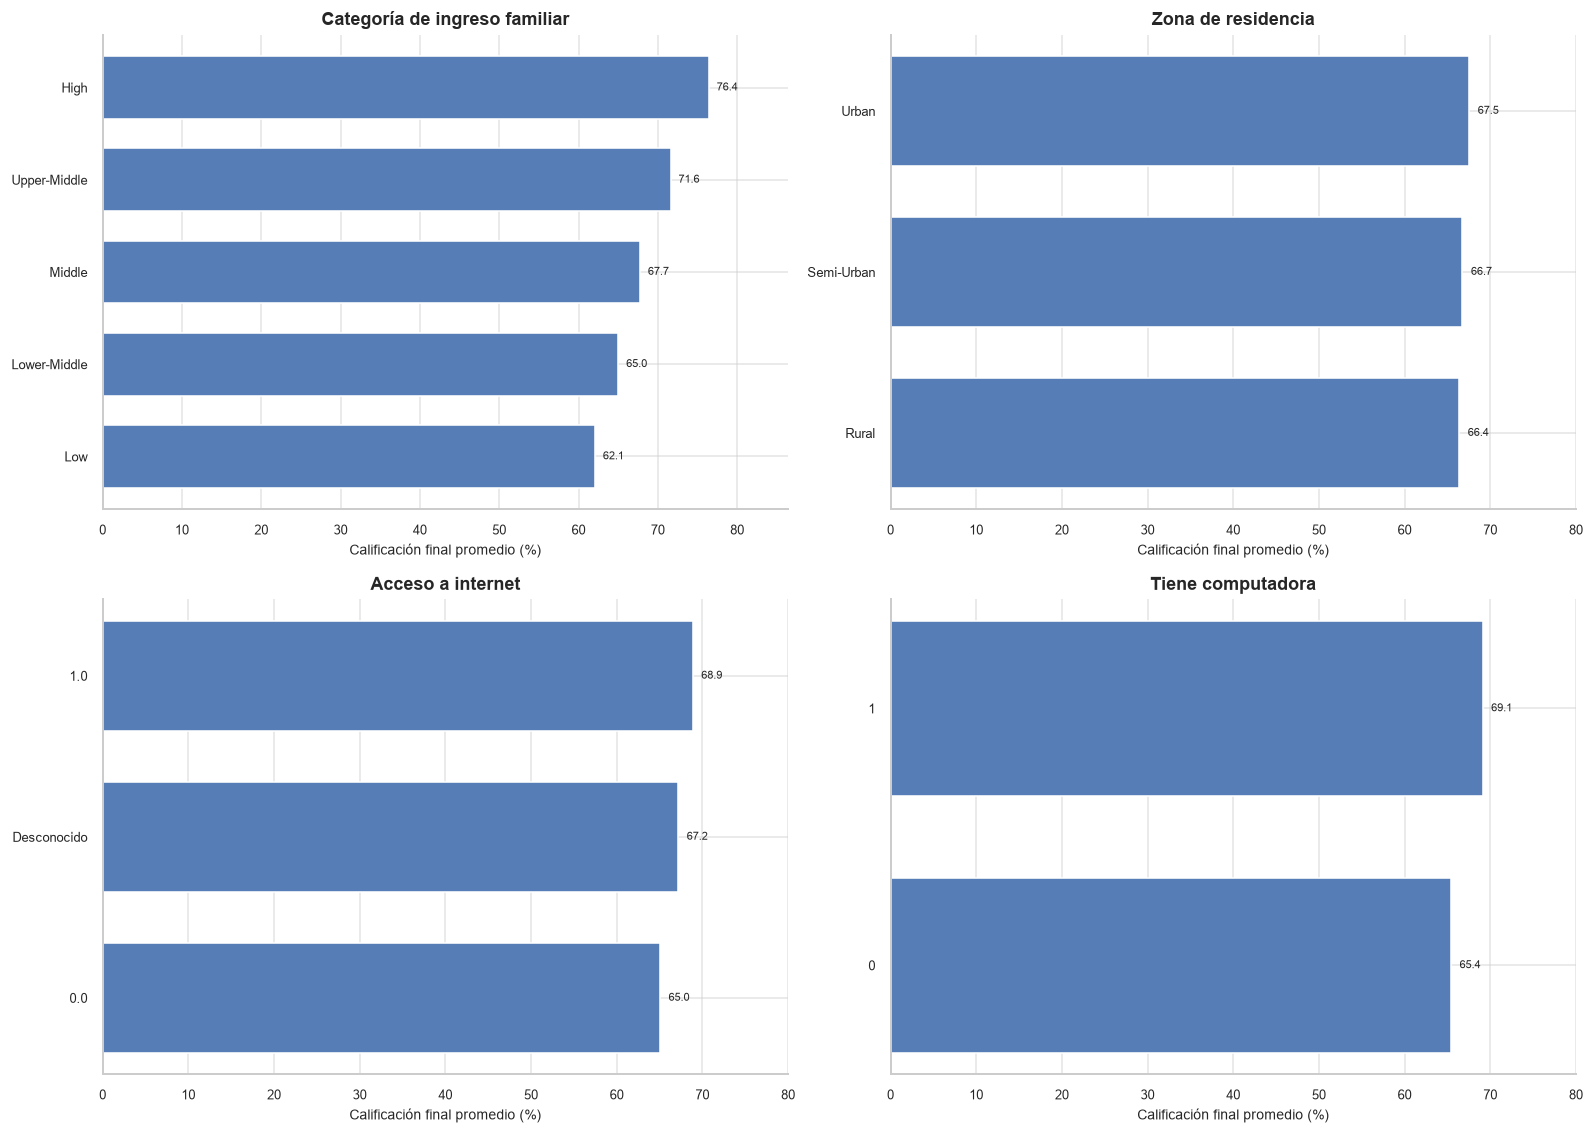

In [29]:

# Variables socioeconómicas
vars_socio = [
    "family_income_bracket",
    "residence_type",
    "has_internet_access",
    "has_computer_or_laptop"
]

fig, ejes = plt.subplots(2, 2, figsize=(14, 10))

for ax, col in zip(ejes.flat, vars_socio):
    grafico_medias(col, ax)

    # Quitar (n=...) y conservar únicamente el promedio
    for texto in ax.texts:
        texto.set_text(
            texto.get_text().split(" (n=")[0]
        )

plt.tight_layout()
plt.show()



**Interpretación de resultados:**

1. **Ingresos familiares:** se observan diferencias importantes en el rendimiento académico según la categoría de ingresos. Los estudiantes de familias con mayores ingresos tienden a presentar calificaciones superiores, con diferencias de hasta 14,35 puntos porcentuales entre los grupos comparados.

2. **Zona de residencia:** las diferencias entre estudiantes de zonas rurales, semiurbanas y urbanas son relativamente pequeñas. Esto sugiere que la zona de residencia presenta una asociación menos marcada con el rendimiento que la categoría de ingresos familiares.

3. **Acceso a internet:** el gráfico permite comparar el rendimiento según la disponibilidad de conexión. Sin embargo, la categoría `Desconocido` corresponde a información faltante y no debe interpretarse como una condición real de acceso.

4. **Disponibilidad de computadora:** se compara el rendimiento académico entre estudiantes que cuentan o no con una computadora. Las diferencias observadas deben analizarse junto con las condiciones socioeconómicas, sin asumir una relación causal.

5. **Consideraciones para K-Means:** durante el preprocesamiento se deberá evaluar la utilidad de estas variables, su codificación y el tratamiento de categorías desconocidas, evitando generar distancias artificiales entre características categóricas.

**Conclusión:** los ingresos familiares presentan una de las asociaciones socioeconómicas más destacadas con el rendimiento académico. Las demás características pueden aportar información complementaria, pero no permiten explicar por sí solas las diferencias en las calificaciones.


### 11. Comparación del rendimiento según características familiares

Se visualizan las medias por nivel educativo y composición del hogar. La categoría `Desconocido` se mantiene explícita para no asignar datos que no se conocen.

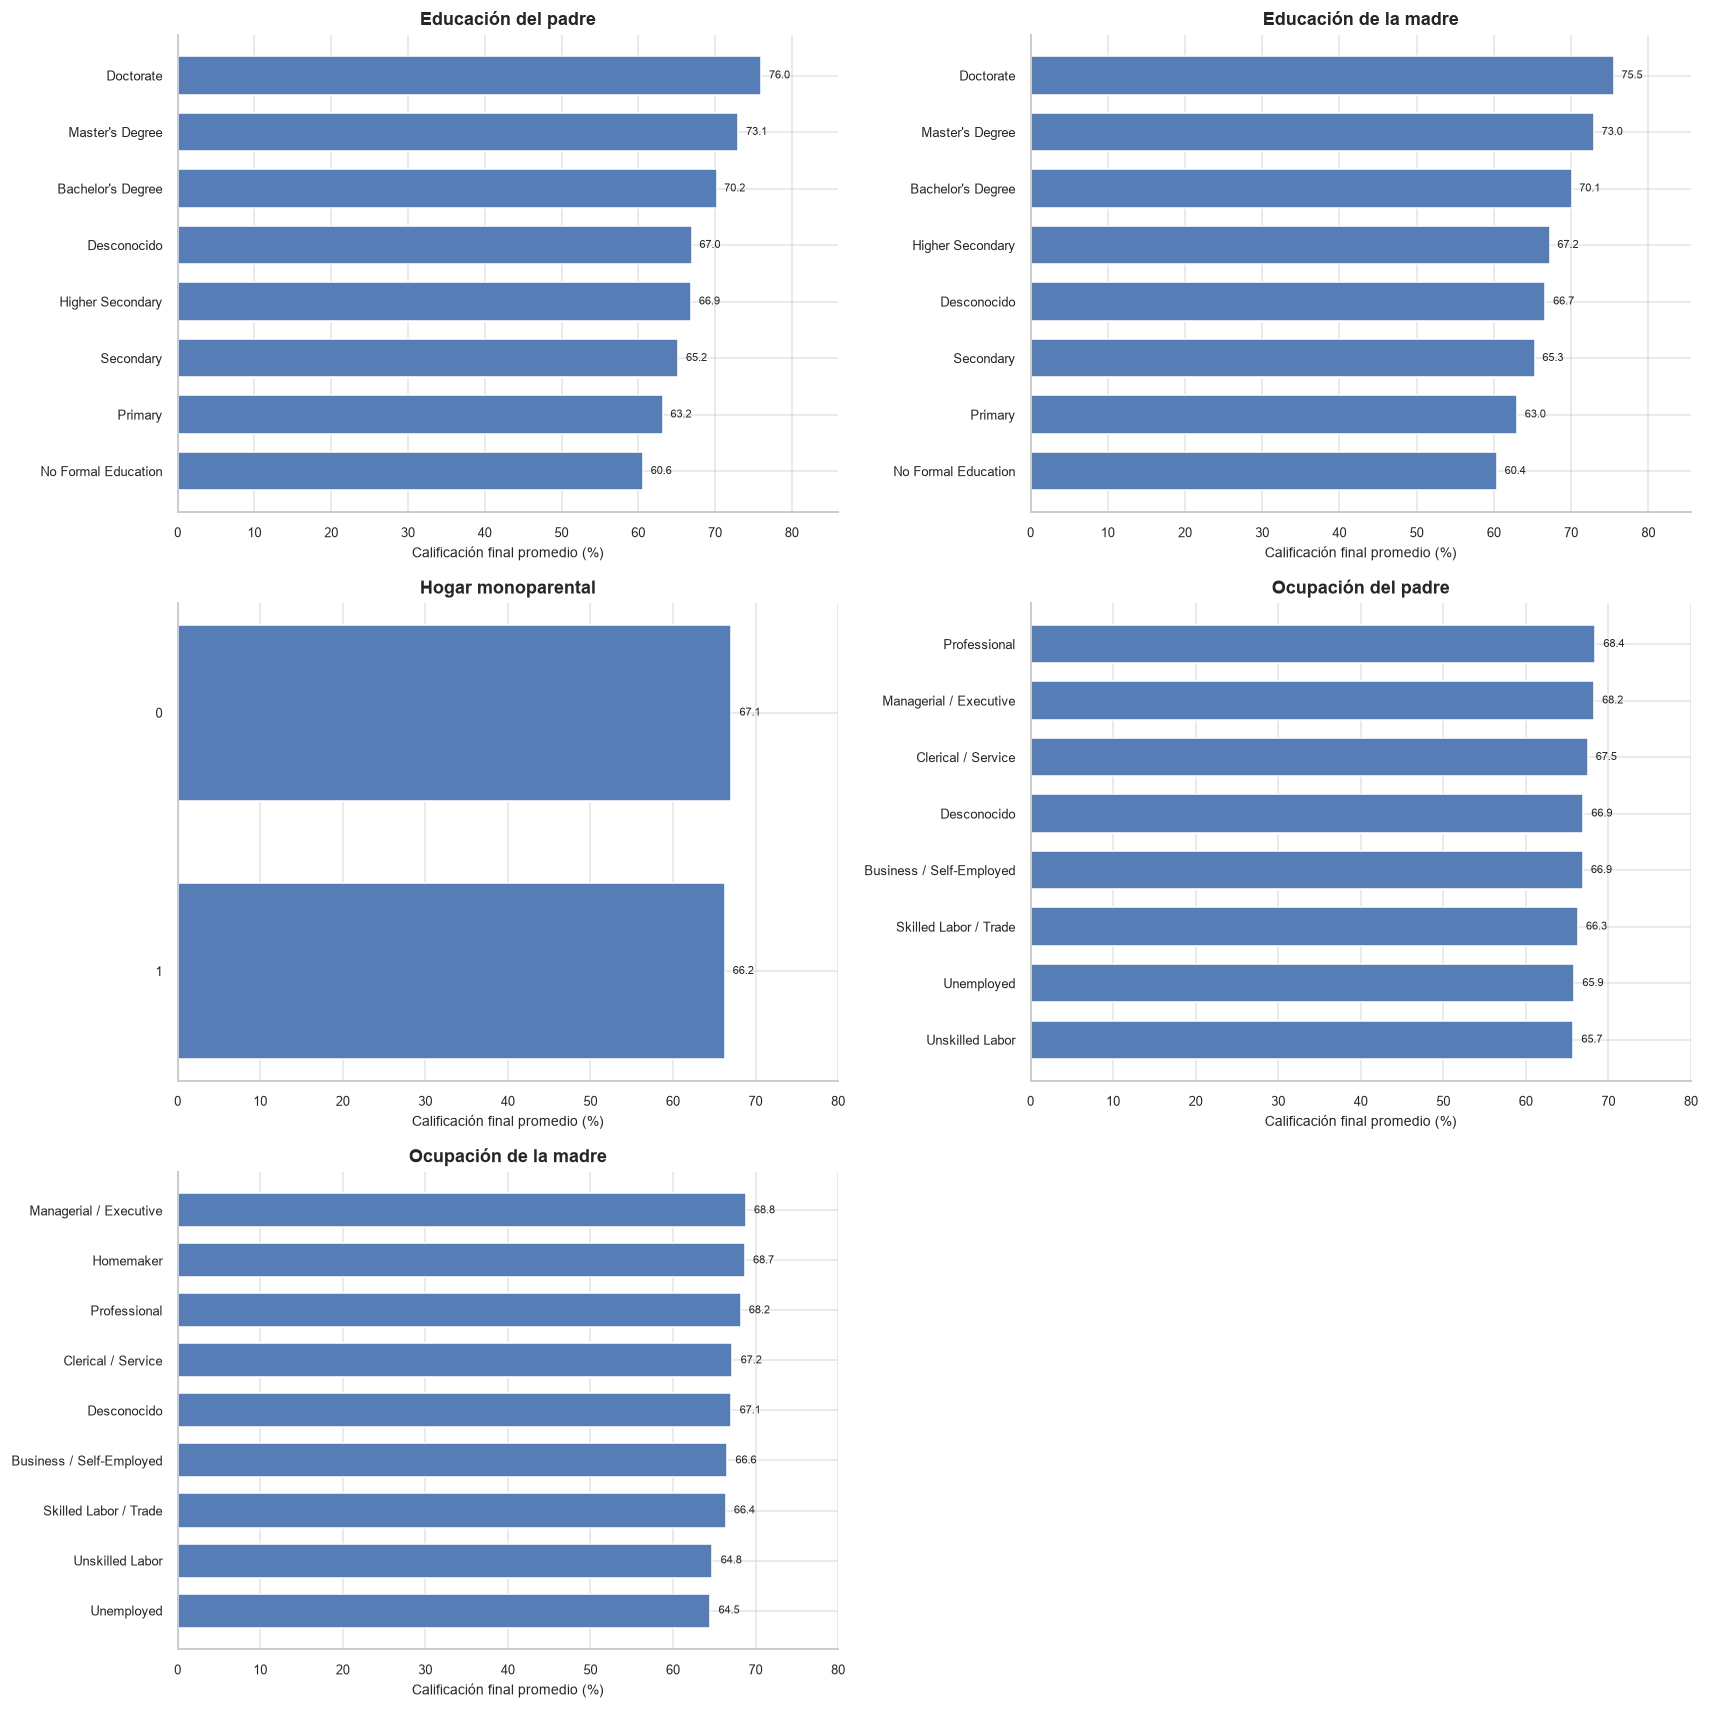

In [28]:

# Variables relacionadas con las características familiares
vars_familia = [
    "father_education_level",
    "mother_education_level",
    "single_parent_household",
    "father_occupation",
    "mother_occupation"
]

fig, ejes = plt.subplots(3, 2, figsize=(15, 15))

for ax, col in zip(ejes.flat, vars_familia):
    grafico_medias(col, ax, max_categorias=10)

    # Eliminar (n=...) y conservar el promedio
    for texto in ax.texts:
        texto.set_text(
            texto.get_text().split(" (n=")[0]
        )

ejes.flat[-1].set_axis_off()

plt.tight_layout()
plt.show()



**Interpretación de resultados:**

1. **Educación del padre:** se observaron diferencias de hasta 15,41 puntos porcentuales entre las calificaciones promedio de los niveles educativos comparados, lo que sugiere una asociación entre la formación académica del padre y el rendimiento estudiantil.

2. **Educación de la madre:** también se identificaron diferencias importantes entre los grupos, alcanzando aproximadamente 15,12 puntos porcentuales. Esto indica que el nivel educativo de los padres puede estar relacionado con las condiciones académicas de los estudiantes.

3. **Hogares monoparentales:** la comparación permite observar posibles diferencias de rendimiento entre estudiantes de hogares con uno o dos progenitores. Estas diferencias deben interpretarse considerando otros factores familiares y socioeconómicos.

4. **Ocupación de los padres:** las comparaciones muestran cómo varía el rendimiento promedio entre las categorías ocupacionales. Sin embargo, estas diferencias no deben atribuirse exclusivamente a la profesión de los padres.

5. **Valores desconocidos:** las categorías `Desconocido` corresponden a información faltante tratada durante el ETL y no representan características familiares reales. Por tanto, sus resultados deben interpretarse con precaución.

6. **Consideraciones para K-Means:** durante el preprocesamiento será necesario evaluar la utilidad de las características familiares, la codificación de las categorías y el tratamiento de los valores desconocidos, evitando introducir distancias artificiales entre categorías.

**Conclusión:** se identificaron diferencias de rendimiento académico entre algunos grupos familiares, especialmente según el nivel educativo de los padres. No obstante, estas diferencias son descriptivas y no demuestran relaciones de causa y efecto.


### 12. Comparación del rendimiento según hábitos de estudio y asistencia

La dispersión permite explorar si las notas tienden a variar con las horas de estudio, asistencia y calificación previa. Para mantener legibilidad se representa una muestra reproducible, pero las correlaciones se calculan con todos los registros disponibles.

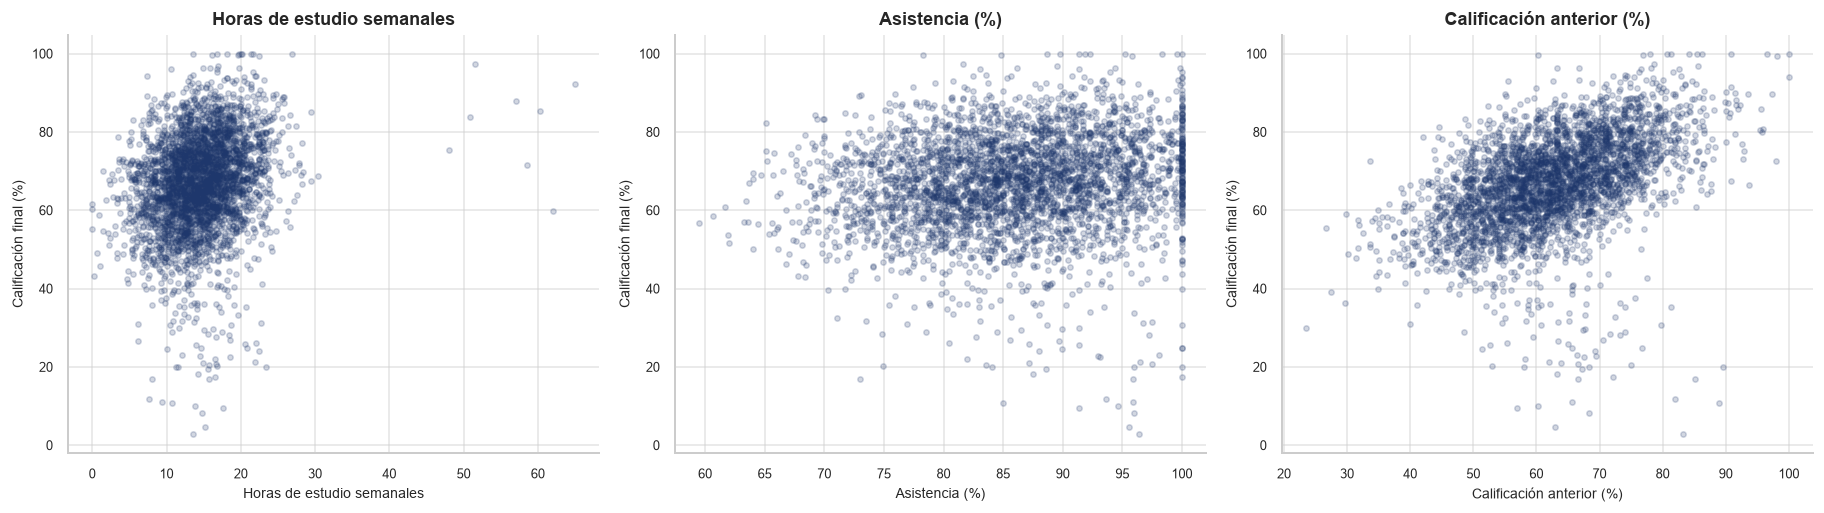

In [25]:

# Variables relacionadas con los hábitos y rendimiento académico
vars_habitos = [
    "study_hours_per_week",
    "attendance_rate_pct",
    "previous_year_grade_pct"
]

# Muestra para visualizar los datos
muestreo = base.sample(
    n=min(len(base), 3500),
    random_state=42
)

# Generar gráficos de dispersión
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.6))

for ax, col in zip(ejes.flat, vars_habitos):
    ax.scatter(
        muestreo[col],
        muestreo[objetivo],
        s=11,
        alpha=0.20,
        color=AZUL,
        rasterized=True
    )

    ax.set(
        title=etiquetas[col],
        xlabel=etiquetas[col],
        ylabel="Calificación final (%)"
    )

plt.tight_layout()
plt.show()



**Interpretación de resultados:**

1. **Horas de estudio semanales:** se observa una relación positiva débil con la calificación final (Spearman = 0,24). La mayoría de los estudiantes concentra sus horas de estudio en un intervalo relativamente similar, aunque existen casos con pocas horas y buenas calificaciones, así como estudiantes que estudian más y obtienen resultados bajos.

2. **Porcentaje de asistencia:** presenta una asociación positiva débil (Spearman = 0,18). Los estudiantes con mayor asistencia tienden a obtener calificaciones ligeramente superiores, pero existe una dispersión considerable y la asistencia elevada no garantiza buenas notas.

3. **Calificación del año anterior:** muestra la relación positiva más destacada (Spearman = 0,54). Los estudiantes con mejores calificaciones anteriores tienden a mantener un rendimiento académico superior, aunque existen excepciones.

4. **Patrones y valores extremos:** se identifican observaciones alejadas de las principales concentraciones de datos, especialmente en las horas de estudio y las calificaciones. Estos casos deben analizarse antes del preprocesamiento, sin considerarlos automáticamente errores.

5. **Consideraciones para K-Means:** será necesario evaluar las distribuciones, escalas y valores extremos de estas variables, ya que pueden influir en las distancias utilizadas para formar los clústeres.

**Conclusión:** entre las tres variables analizadas, el rendimiento académico anterior presenta la asociación más fuerte con la calificación final. Las horas de estudio y la asistencia muestran relaciones positivas más débiles, por lo que ninguna de estas características explica por sí sola las diferencias de rendimiento.


### 13. Comparación del rendimiento según características escolares

Se contrastan medias según tipo de centro, grado, período académico y beca, considerando el tamaño de los grupos.

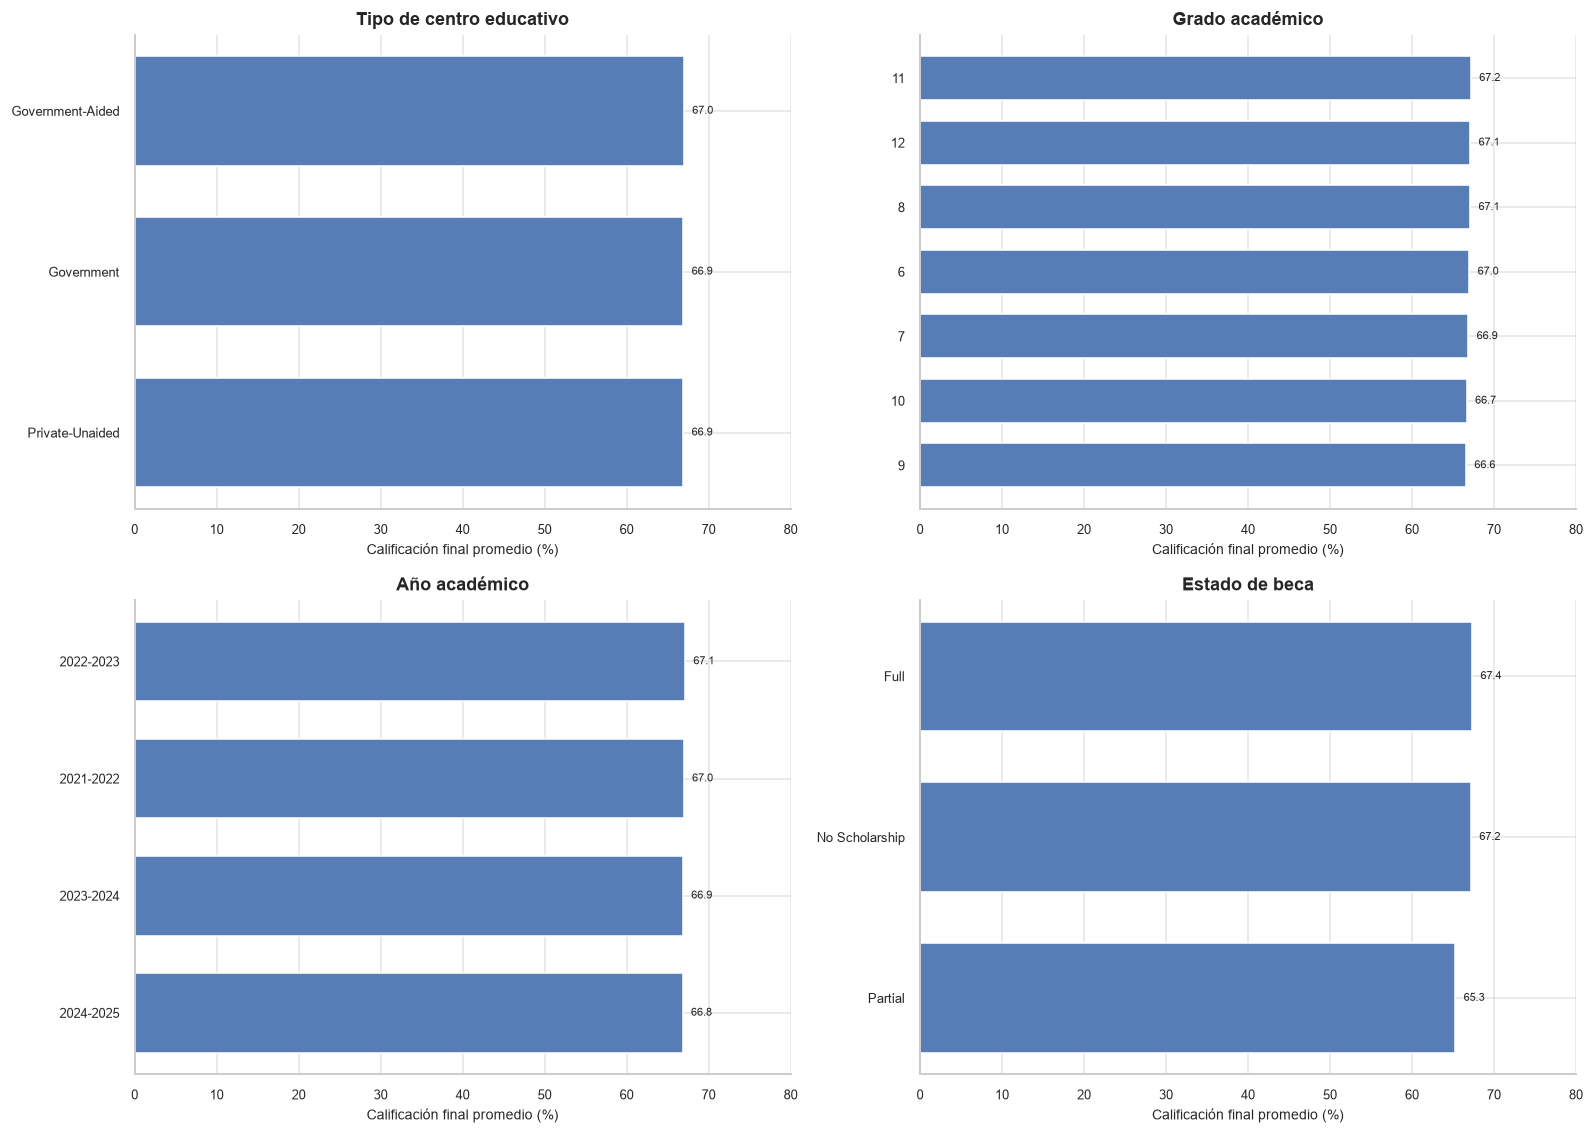

In [24]:

vars_escuela = [
    "school_type",
    "grade_level",
    "academic_year",
    "scholarship_status"
]

fig, ejes = plt.subplots(2, 2, figsize=(14, 10))

for ax, col in zip(ejes.flat, vars_escuela):
    grafico_medias(col, ax, max_categorias=12)

    # Mostrar únicamente el promedio, sin (n=...)
    for texto in ax.texts:
        texto.set_text(texto.get_text().split(" (n=")[0])

plt.tight_layout()
plt.show()



**Interpretación de resultados:**

1. **Tipo de centro educativo:** las diferencias de rendimiento entre los tipos de colegio deben evaluarse según sus promedios. No se observa una relación tan destacada como la encontrada anteriormente con los ingresos familiares.

2. **Grado académico:** la comparación permite identificar posibles variaciones entre niveles educativos, aunque estas diferencias no necesariamente indican que cursar un grado determinado produzca mejores calificaciones.

3. **Año académico:** el rendimiento promedio presentó pequeñas variaciones entre los periodos analizados. El promedio más alto se registró en 2022-2023 (aproximadamente 67,14 %) y el más bajo en 2024-2025 (66,85 %), una diferencia de apenas 0,29 puntos porcentuales.

4. **Estado de beca:** la comparación permite examinar posibles diferencias de rendimiento entre estudiantes según su condición de beca. Estas diferencias deben interpretarse considerando también las características económicas y académicas de cada grupo.

5. **Consideraciones para K-Means:** durante el preprocesamiento se deberá evaluar si estas variables aportan información útil para diferenciar perfiles de estudiantes, evitando incluir características redundantes o poco informativas.

En general, las características escolares pueden presentar diferencias descriptivas en el rendimiento, pero los gráficos no permiten establecer relaciones causales.


### 14. Análisis visual de relaciones entre variables numéricas (dispersión)

Se revisan variables económicas, familiares y de accesibilidad que podrían relacionarse con el rendimiento. Los ingresos se muestran en escala logarítmica únicamente para mejorar la lectura de valores de diferente magnitud.

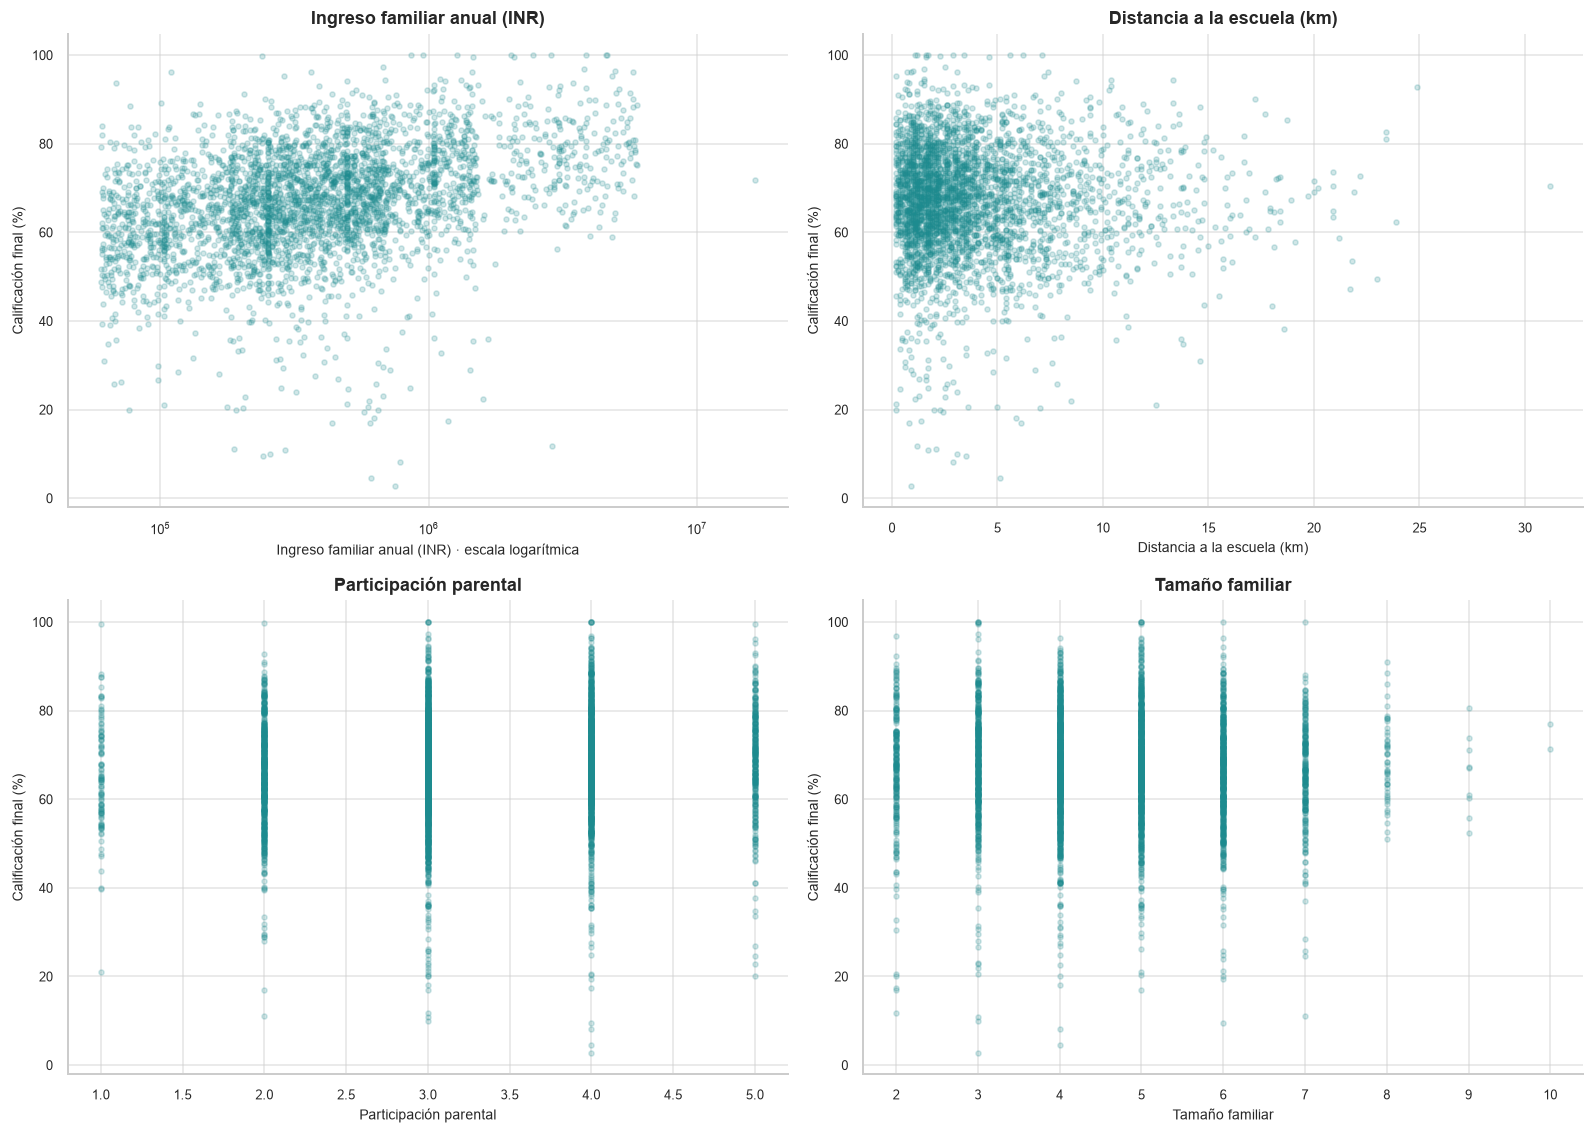

In [22]:
vars_disp = ["annual_family_income_inr", "distance_to_school_km",
             "parental_involvement_score", "family_size"]
fig, ejes = plt.subplots(2, 2, figsize=(14, 10))
for ax, col in zip(ejes.flat, vars_disp):
    x=muestreo[col]; y=muestreo[objetivo]
    mascara=x.notna() & y.notna()
    ax.scatter(x[mascara], y[mascara], s=10, alpha=.2, color=TURQUESA, rasterized=True)
    if col == "annual_family_income_inr" and (x[mascara] > 0).all():
        ax.set_xscale("log")
        ax.set_xlabel(etiquetas[col] + " · escala logarítmica")
    else: ax.set_xlabel(etiquetas[col])
    ax.set(title=etiquetas[col], ylabel="Calificación final (%)")
plt.tight_layout(); plt.show()


**Interpretación de resultados:**

1. **Ingresos familiares:** se observa una tendencia positiva entre el ingreso familiar anual y la calificación final (Spearman = 0,37). Los estudiantes de mayores ingresos tienden a presentar mejores resultados académicos, aunque existen excepciones.

2. **Distancia al centro educativo:** presenta una correlación prácticamente nula con la calificación final (Spearman = -0,03). Esto indica que no se identifica una relación destacada entre ambas variables.

3. **Participación de los padres:** muestra una asociación positiva débil con el rendimiento académico (Spearman = 0,10), por lo que una mayor participación parental no siempre está acompañada de calificaciones superiores.

4. **Tamaño familiar:** presenta una correlación negativa muy débil (Spearman = -0,05). No se observa una relación importante entre la cantidad de integrantes del hogar y las calificaciones.

5. **Comparación general:** de las cuatro variables analizadas, el ingreso familiar presenta la asociación más destacada con el rendimiento académico. Las demás muestran relaciones débiles o prácticamente nulas.

6. **Consideraciones para K-Means:** durante el preprocesamiento será necesario evaluar la escala, distribución, valores atípicos y posible redundancia de estas variables antes de seleccionarlas para el agrupamiento.

En general, los gráficos muestran que las condiciones económicas presentan una asociación más marcada con las calificaciones que la distancia escolar, la participación parental o el tamaño familiar. Sin embargo, estas relaciones no permiten establecer causalidad.


### 15. Matriz de correlación y mapa de calor

Se visualizan las relaciones de Pearson y Spearman entre las variables numéricas. Se excluyen identificadores, `grade_class` y `at_risk_flag` para no confundir categorías derivadas con predictores independientes.

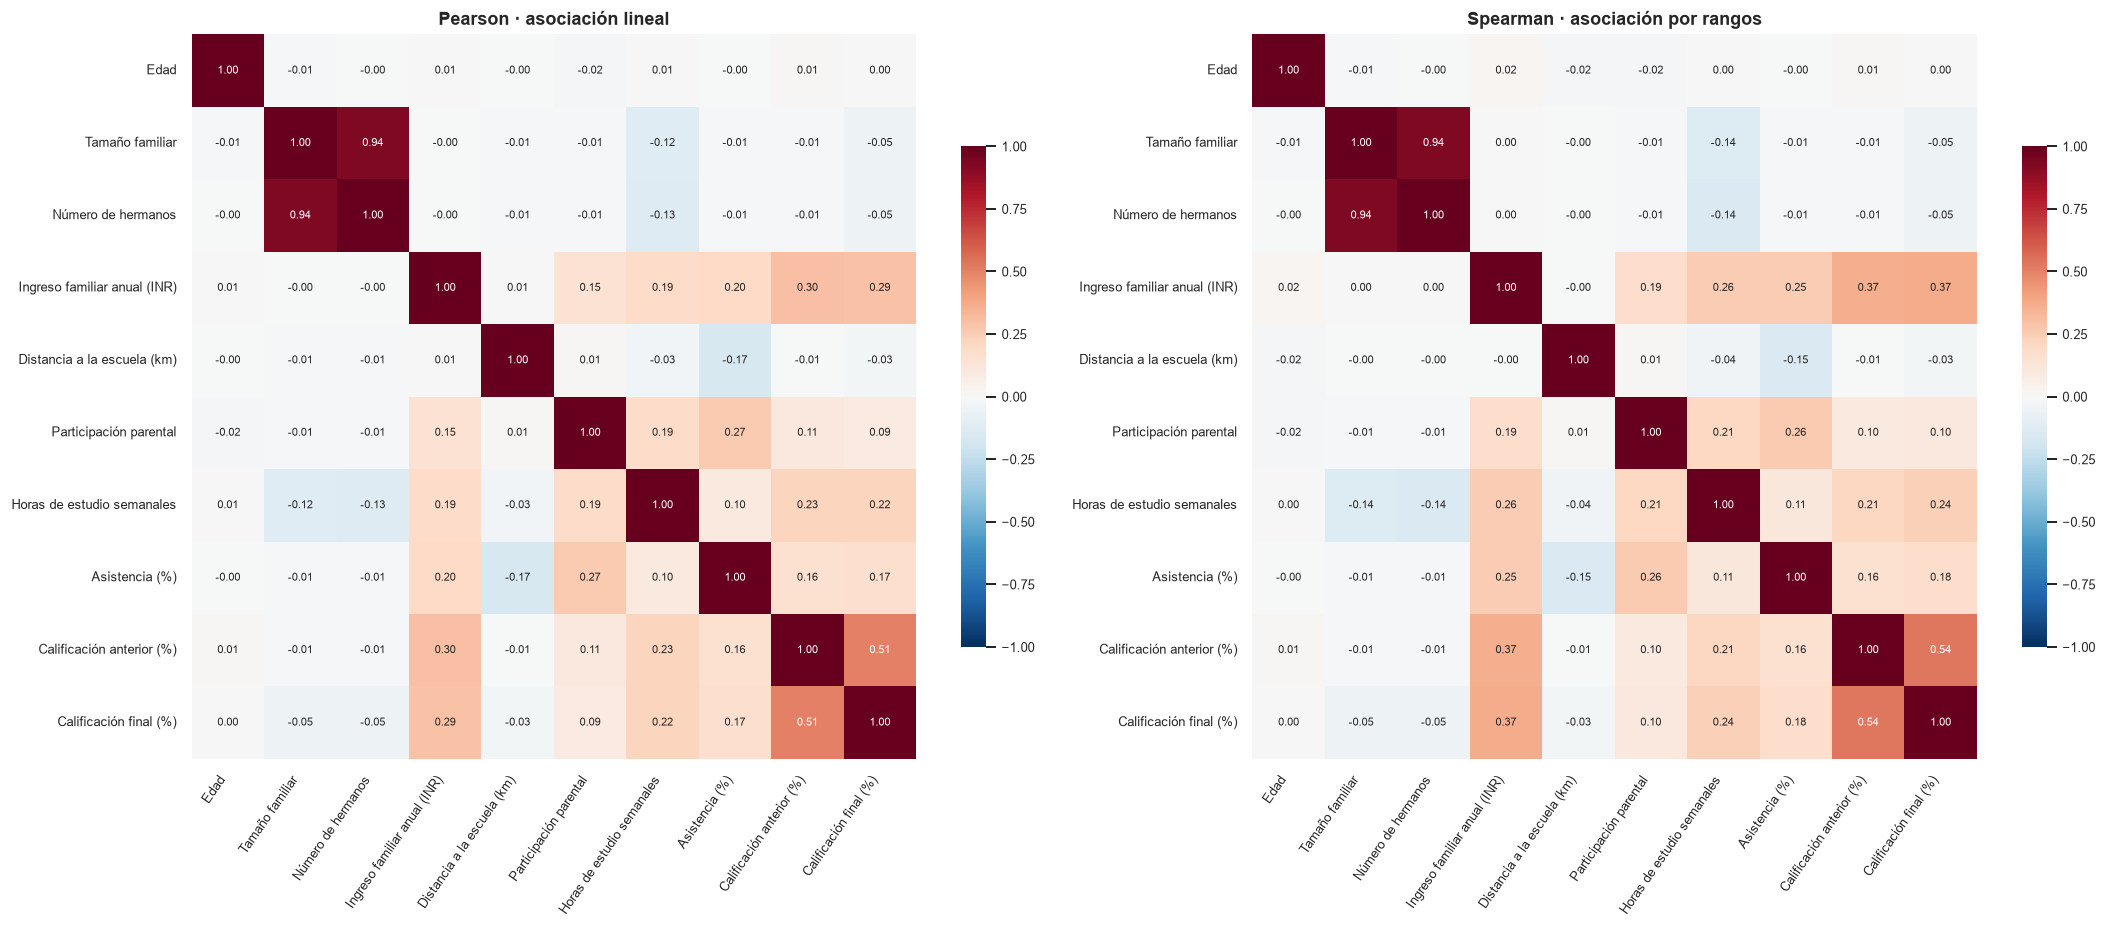

In [21]:
corr_cols = [c for c in numericas if base[c].nunique(dropna=True) > 1]
corr_p = base[corr_cols].corr(method="pearson")
corr_s = base[corr_cols].corr(method="spearman")
fig, ejes = plt.subplots(1,2,figsize=(19,8))
for ax, mat, titulo in zip(ejes, [corr_p,corr_s], ["Pearson · asociación lineal", "Spearman · asociación por rangos"]):
    nombres=[etiquetas[c] for c in mat.columns]
    mat2=mat.rename(index=etiquetas, columns=etiquetas)
    sns.heatmap(mat2, ax=ax, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
                annot=True, fmt=".2f", annot_kws={"size":7}, square=True,
                cbar_kws={"shrink":.65})
    ax.set_title(titulo)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=55, ha="right", fontsize=8)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=8)
plt.tight_layout(); plt.show()


**Interpretación de resultados:**

1. **Rendimiento académico:** la calificación del año anterior presentó la mayor asociación positiva con la calificación final (Spearman = 0,54), lo que indica que los estudiantes con mejores resultados anteriores tienden a mantener un mayor rendimiento.

2. **Condiciones socioeconómicas:** el ingreso familiar anual mostró una correlación positiva con la calificación final (Spearman = 0,37), sugiriendo una relación entre las condiciones económicas y el desempeño académico.

3. **Hábitos académicos:** las horas de estudio (0,24) y la asistencia (0,18) presentaron asociaciones positivas, aunque relativamente débiles. Esto indica que el rendimiento no depende únicamente de estos factores.

4. **Características personales y familiares:** la edad, el número de hermanos y el tamaño familiar presentaron correlaciones muy bajas con la calificación final, por lo que no muestran una relación directa destacada en este análisis.

5. **Relaciones entre variables:** se identificaron asociaciones entre algunas características, como el tamaño familiar y el número de hermanos (0,94), lo que evidencia la presencia de información potencialmente redundante.

6. **Comparación de métodos:** Pearson y Spearman mostraron tendencias generales similares, aunque algunas correlaciones fueron mayores con Spearman, especialmente la de ingresos familiares y rendimiento académico.

7. **Consideraciones para K-Means:** será importante evaluar las variables altamente correlacionadas, su escala y la presencia de valores atípicos durante el preprocesamiento, para evitar que determinadas características influyan excesivamente en la formación de los clústeres.

En general, los resultados muestran que el rendimiento académico está asociado con distintos factores, principalmente el desempeño anterior y las condiciones socioeconómicas. Sin embargo, las correlaciones no permiten establecer relaciones de causa y efecto.


### 16. Análisis de patrones y tendencias del rendimiento académico

Se muestran promedios según año académico y un cruce entre zona de residencia y categoría de ingresos. Las celdas con menos de 30 estudiantes se omiten para evitar interpretaciones frágiles.

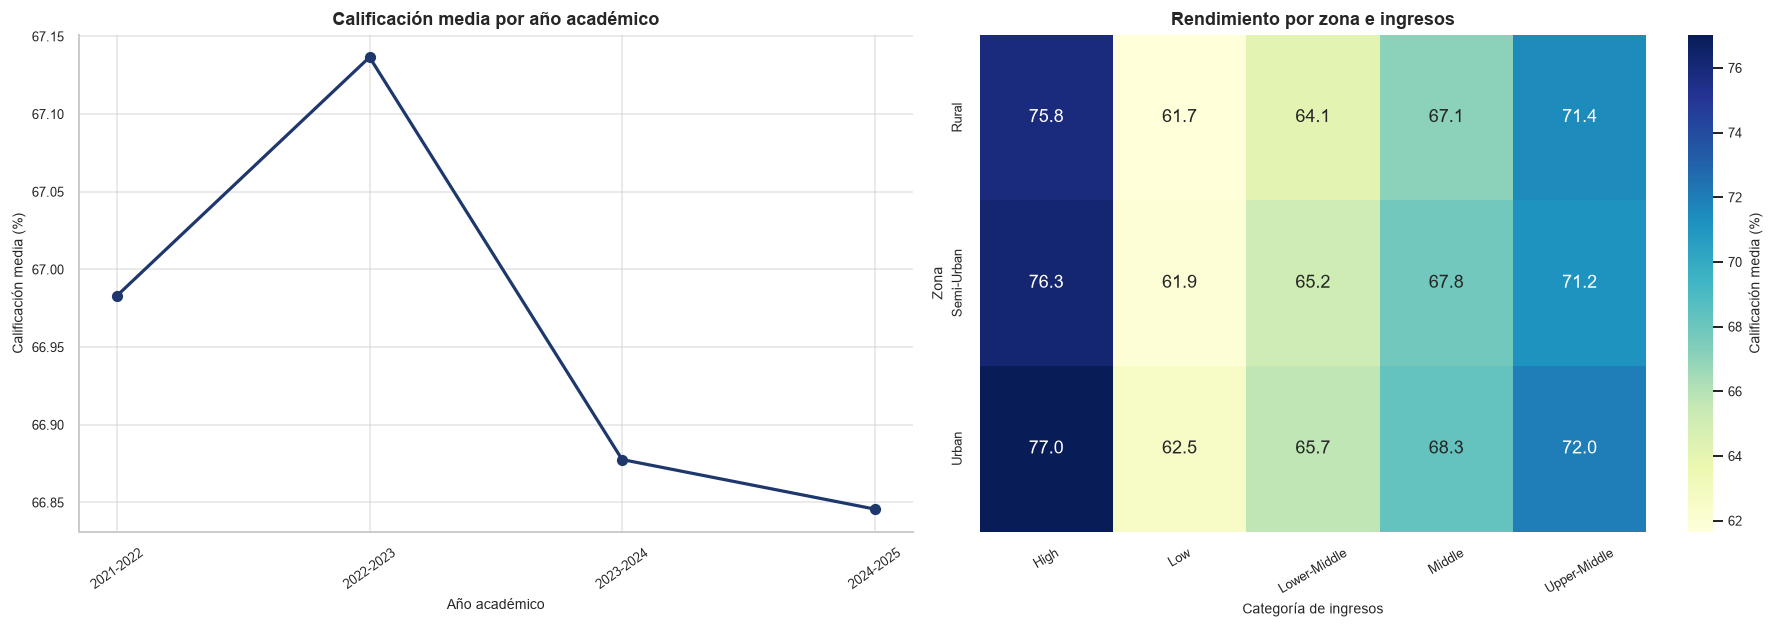

**Interpretación:** Las medias por año académico varían entre **66.85 %** y **67.14 %**. El mapa muestra diferencias conjuntas entre zonas e ingresos; no permite atribuir causalidad ni inferir una tendencia temporal individual.

In [16]:
    fig, ejes = plt.subplots(1,2,figsize=(16,5.6))
por_anio=tabla_grupos("academic_year")
if len(por_anio):
    p=por_anio.sort_values("Grupo")
    ejes[0].plot(p["Grupo"],p["media"],marker="o",color=AZUL,linewidth=2)
    ejes[0].set(title="Calificación media por año académico", xlabel="Año académico", ylabel="Calificación media (%)")
    ejes[0].tick_params(axis="x", rotation=35)
else:
    ejes[0].text(.5,.5,"No hay grupos suficientes",ha="center",va="center")

combinacion = (base.assign(Zona=base["residence_type"].astype(str),
                          Ingreso=base["family_income_bracket"].astype(str))
               .groupby(["Zona","Ingreso"])[objetivo].agg(["mean","count"]).reset_index())
combinacion["media_valida"] = combinacion["mean"].where(combinacion["count"] >= 30)
matriz = combinacion.pivot(index="Zona", columns="Ingreso", values="media_valida")
if matriz.notna().any().any():
    sns.heatmap(matriz, annot=True, fmt=".1f", cmap="YlGnBu", ax=ejes[1],
                cbar_kws={"label":"Calificación media (%)"})
    ejes[1].set(title="Rendimiento por zona e ingresos", xlabel="Categoría de ingresos", ylabel="Zona")
    ejes[1].tick_params(axis="x",rotation=30)
else:
    ejes[1].text(.5,.5,"No hay cruces con al menos 30 estudiantes",ha="center",va="center")
plt.tight_layout(); plt.show()

if len(por_anio)>=2:
    interpretar(f"Las medias por año académico varían entre **{por_anio['media'].min():.2f} %** "
               f"y **{por_anio['media'].max():.2f} %**. El mapa muestra diferencias conjuntas "
               "entre zonas e ingresos; no permite atribuir causalidad ni inferir una tendencia temporal individual.")
else:
    interpretar("El cruce entre zona e ingresos muestra variaciones descriptivas; solo se presentan grupos con muestra suficiente.")


**Interpretación de resultados:**

La calificación media presentó una ligera disminución después del periodo académico 2022-2023, pasando de aproximadamente 67,14 % a 66,85 % en 2024-2025. Aunque este comportamiento coincide con el periodo posterior a las principales restricciones de la pandemia, no existen evidencias suficientes para atribuirle directamente esta variación.

Por otra parte, se observaron diferencias más marcadas en el rendimiento según la categoría de ingresos familiares. Los estudiantes de mayores ingresos presentaron calificaciones promedio superiores, mientras que las diferencias entre zonas de residencia fueron menores.

Estos resultados sugieren una asociación más marcada del rendimiento con las condiciones socioeconómicas que con la zona de residencia o el año académico, sin establecer relaciones causales.


### 17. Comparación visual de grupos de estudiantes

Se contrastan combinaciones de características de los estudiantes. Las barras muestran medias, con tamaños mínimos de grupo; no equivalen a diferencias causalmente demostradas.

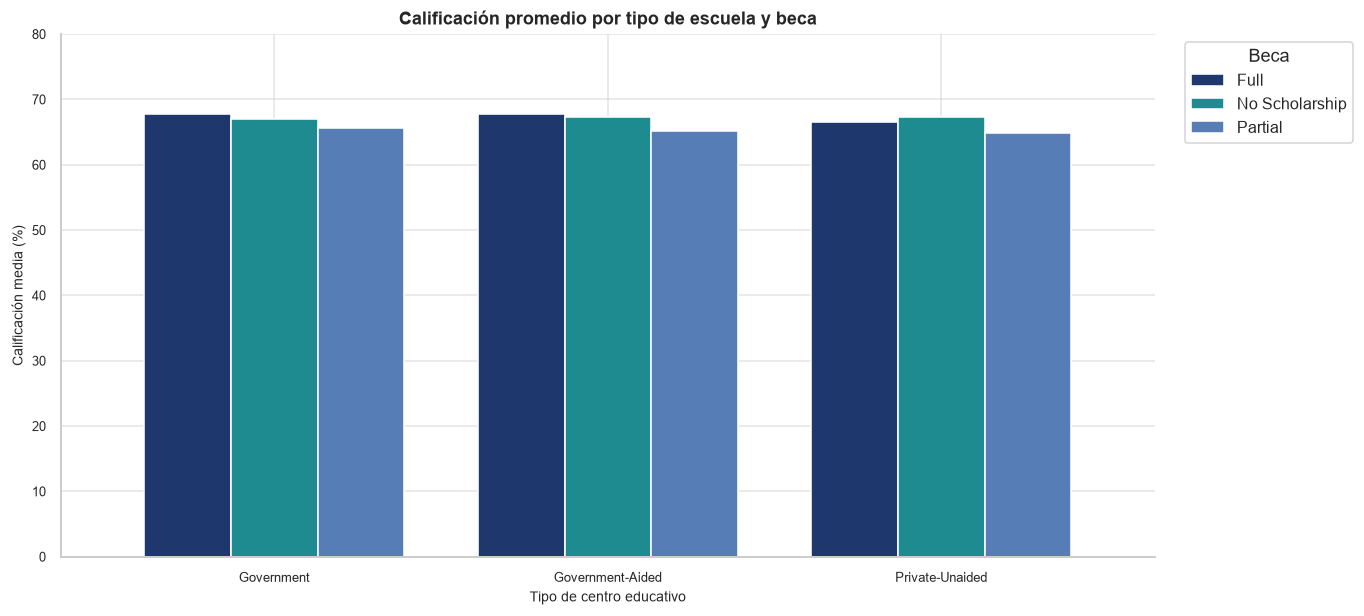

**Interpretación:** Entre las combinaciones con al menos 30 estudiantes, la mayor media es **67.80 %** (Government-Aided / Full, n=190) y la menor **64.91 %** (Private-Unaided / Partial, n=657). Pueden intervenir otras diferencias entre los grupos.

In [17]:
# Comparación cruzada: beca y tipo de centro educativo.
cruce = (base.assign(Beca=base["scholarship_status"].astype(str),
                    Escuela=base["school_type"].astype(str))
         .groupby(["Escuela","Beca"])[objetivo].agg(n="count",media="mean").reset_index())
cruce = cruce[cruce["n"] >= 30].copy()
fig, ax=plt.subplots(figsize=(12,5.5))
if not cruce.empty:
    tabla_cruce=cruce.pivot(index="Escuela",columns="Beca",values="media")
    tabla_cruce.plot.bar(ax=ax,width=.78, color=PALETA[:len(tabla_cruce.columns)],edgecolor="white")
    ax.set(title="Calificación promedio por tipo de escuela y beca",
           xlabel="Tipo de centro educativo",ylabel="Calificación media (%)")
    ax.legend(title="Beca",bbox_to_anchor=(1.02,1),loc="upper left")
    ax.tick_params(axis="x",rotation=0)
    ax.set_ylim(0, min(102, max(80, cruce["media"].max()+10)))
else:
    ax.text(.5,.5,"No hay combinaciones con al menos 30 estudiantes",
            ha="center",va="center",transform=ax.transAxes)
plt.tight_layout(); plt.show()

if not cruce.empty:
    alta=cruce.loc[cruce["media"].idxmax()]
    baja=cruce.loc[cruce["media"].idxmin()]
    interpretar(f"Entre las combinaciones con al menos 30 estudiantes, la mayor media es "
               f"**{alta['media']:.2f} %** ({alta['Escuela']} / {alta['Beca']}, n={alta['n']}) "
               f"y la menor **{baja['media']:.2f} %** ({baja['Escuela']} / {baja['Beca']}, n={baja['n']}). "
               "Pueden intervenir otras diferencias entre los grupos.")
else:
    interpretar("Las combinaciones disponibles no alcanzan el tamaño mínimo definido para comparaciones visuales.")

### 18. Identificación de hallazgos visuales relevantes

Se sintetizan las observaciones con respaldo cuantitativo. **Las variables con valores atípicos o asociaciones marcadas deben revisarse al diseñar las variables, transformaciones y escalado de K-Means.** No se eliminan observaciones ni se entrena el modelo en este apartado.

In [18]:
hallazgos_visuales=[]
if len(corr_final):
    for col,rho in corr_final.head(3).items():
        hallazgos_visuales.append({
            "Eje": "Relación numérica",
            "Hallazgo": etiquetas[col],
            "Evidencia": f"Spearman = {rho:+.3f}",
            "Implicación posterior": "Evaluar asociación y posible redundancia entre variables"
        })
for _,r in tabla_atipicos.head(3).iterrows():
    if r["N fuera de 1,5×IQR"] > 0:
        hallazgos_visuales.append({
            "Eje": "Valores atípicos",
            "Hallazgo": r["Variable"],
            "Evidencia": f"{r['N fuera de 1,5×IQR']} casos ({r['Porcentaje (%)']:.2f} %) fuera de IQR",
            "Implicación posterior": "Comparar escalado/transformación y sensibilidad de K-Means"
        })
for col in ["family_income_bracket","father_education_level","mother_education_level"]:
    t=tabla_grupos(col)
    if len(t)>1:
        hallazgos_visuales.append({
            "Eje": "Diferencia entre grupos", "Hallazgo": etiquetas[col],
            "Evidencia": f"Brecha entre medias de {t['media'].max()-t['media'].min():.2f} puntos",
            "Implicación posterior": "Describir grupos sin atribuir causalidad"
        })
tabla_hallazgos_visuales=pd.DataFrame(hallazgos_visuales)
display(tabla_hallazgos_visuales)
interpretar("Los patrones deben contrastarse con las distribuciones y los tamaños de grupo. "
           "Para K-Means, se recomienda evaluar las distancias y estabilidad de conglomerados "
           "antes y después de posibles transformaciones, sin suponer que todo atípico es un error.")

,Eje,Hallazgo,Evidencia,Implicación posterior
0,Relación numérica,Calificación anterior (%),Spearman = +0.535,Evaluar asociación y posible redundancia entre...
1,Relación numérica,Ingreso familiar anual (INR),Spearman = +0.370,Evaluar asociación y posible redundancia entre...
2,Relación numérica,Horas de estudio semanales,Spearman = +0.239,Evaluar asociación y posible redundancia entre...
3,Valores atípicos,Ingreso familiar anual (INR),1192 casos (9.93 %) fuera de IQR,Comparar escalado/transformación y sensibilida...
4,Valores atípicos,Distancia a la escuela (km),688 casos (5.73 %) fuera de IQR,Comparar escalado/transformación y sensibilida...
5,Valores atípicos,Participación parental,339 casos (2.83 %) fuera de IQR,Comparar escalado/transformación y sensibilida...
6,Diferencia entre grupos,Categoría de ingreso familiar,Brecha entre medias de 14.35 puntos,Describir grupos sin atribuir causalidad
7,Diferencia entre grupos,Educación del padre,Brecha entre medias de 15.41 puntos,Describir grupos sin atribuir causalidad
8,Diferencia entre grupos,Educación de la madre,Brecha entre medias de 15.12 puntos,Describir grupos sin atribuir causalidad


**Interpretación:** Los patrones deben contrastarse con las distribuciones y los tamaños de grupo. Para K-Means, se recomienda evaluar las distancias y estabilidad de conglomerados antes y después de posibles transformaciones, sin suponer que todo atípico es un error.


### 19. Resumen de resultados del análisis visual

El análisis exploratorio visual del dataset **Student Grade SES** permitió identificar patrones relacionados con el rendimiento académico, las condiciones socioeconómicas, las características familiares, los hábitos de estudio y las variables escolares.

Se analizaron **12.000 estudiantes y 29 variables**, utilizando el dataset previamente limpiado.

#### 1. Distribución del rendimiento académico

- La calificación final presentó una media de **66,94 %** y una mediana de **67,30 %**.
- El 50 % central de las calificaciones se encontró entre **60,10 % y 74,60 %**.
- La categoría de calificación más frecuente fue **C**, con aproximadamente el **51,2 %** de los estudiantes.
- Se observaron estudiantes con rendimientos superiores e inferiores a los valores más frecuentes.

#### 2. Condiciones socioeconómicas

- El ingreso familiar anual mostró una asociación positiva con la calificación final (**Spearman = 0,37**).
- Los estudiantes de categorías de ingresos más altos presentaron, en promedio, mejores calificaciones.
- Se observaron diferencias de hasta **14,35 puntos porcentuales** entre categorías de ingresos familiares.
- Las diferencias de rendimiento entre zonas rurales, semiurbanas y urbanas fueron menos marcadas que las diferencias entre categorías de ingresos.
- El acceso a internet y la disponibilidad de computadora se analizaron como características complementarias del entorno socioeconómico.

#### 3. Características familiares

- Los niveles educativos del padre y de la madre presentaron diferencias en el rendimiento promedio de los estudiantes, de hasta **15,41 y 15,12 puntos porcentuales**, respectivamente.
- Las ocupaciones de los padres permitieron comparar distintos perfiles familiares, sin establecer que una profesión determine el rendimiento.
- El tamaño familiar y el número de hermanos presentaron una correlación positiva muy fuerte entre sí (**0,94**), lo que indica información potencialmente redundante.
- El tamaño familiar y el número de hermanos mostraron asociaciones muy débiles con la calificación final.
- Las categorías `Desconocido` corresponden a información faltante tratada durante el ETL y no representan características familiares reales.

#### 4. Hábitos académicos

- Las horas de estudio semanales presentaron una asociación positiva débil con la calificación final (**Spearman = 0,24**).
- Se observó una concentración de estudiantes con cantidades relativamente similares de horas de estudio.
- También se identificaron estudiantes que obtuvieron buenas calificaciones estudiando menos horas y otros que no alcanzaron resultados equivalentes pese a estudiar más.
- La asistencia presentó una asociación positiva débil con el rendimiento (**Spearman = 0,18**). Una mayor asistencia tiende a relacionarse con mejores notas, aunque existen excepciones.
- La calificación del año anterior mostró la asociación positiva más destacada con la calificación final (**Spearman = 0,535**).

#### 5. Características escolares

- Las comparaciones por tipo de colegio y grado académico no mostraron diferencias tan marcadas como las observadas en algunas características socioeconómicas y familiares.
- El rendimiento promedio presentó variaciones pequeñas entre los años académicos.
- Entre 2022-2023 y 2024-2025 se observó una disminución aproximada de **0,29 puntos porcentuales** en la calificación media.
- También se examinaron las diferencias de rendimiento según la condición de beca.
- Las variaciones observadas por año no permiten atribuir cambios directamente a la pandemia u otros acontecimientos externos.

#### 6. Correlaciones y relaciones entre variables

- La calificación anterior y el ingreso familiar anual presentaron las asociaciones numéricas más destacadas con el rendimiento final entre las variables examinadas.
- Las horas de estudio y la asistencia mostraron relaciones positivas, pero de menor magnitud.
- La distancia escolar, la edad y algunas características familiares presentaron correlaciones cercanas a cero con la calificación final.
- Las matrices de Pearson y Spearman permitieron identificar relaciones entre variables y posibles casos de información redundante.

#### 7. Distribuciones y valores atípicos

- Los histogramas mostraron variables con distribuciones y niveles de asimetría diferentes.
- Los ingresos familiares presentaron valores elevados y una distribución asimétrica.
- Los diagramas de caja permitieron identificar observaciones extremas mediante el criterio del rango intercuartílico (IQR).
- También se examinaron posibles valores extremos en la distancia escolar, las horas de estudio, las calificaciones y las características familiares.
- Estos valores se conservaron durante el EDA, ya que su identificación estadística no demuestra que sean errores.

#### 8. Consideraciones sobre la calidad de los datos

- El análisis se realizó sobre un dataset sin valores nulos ni duplicados.
- Algunas variables fueron imputadas durante el ETL, por lo que sus valores estimados pueden influir en las distribuciones y correlaciones observadas.
- Las categorías de calificación y el indicador de riesgo académico pueden depender de la calificación final, por lo que deben tratarse con precaución en los análisis posteriores.

**Resumen general:**

Los resultados muestran que el rendimiento académico presenta asociaciones con múltiples características, principalmente el desempeño anterior y las condiciones socioeconómicas y familiares.

Los hábitos de estudio y la asistencia también muestran relaciones positivas, aunque más débiles. Por otra parte, algunas características escolares y demográficas presentan diferencias relativamente pequeñas.

Además, se identificaron variables redundantes, distribuciones asimétricas y valores atípicos que deberán evaluarse durante el preprocesamiento para K-Means.



### 20. Conclusiones finales de la Parte 03: Análisis visual

El análisis exploratorio visual permitió complementar los resultados estadísticos e identificar patrones en el rendimiento académico de los estudiantes y sus diferentes características.

A partir de los resultados obtenidos, se establecen las siguientes conclusiones:

#### 1. El rendimiento académico está asociado con diferentes factores

Las calificaciones finales presentan asociaciones con características académicas, socioeconómicas y familiares.

La calificación del año anterior mostró la relación positiva más destacada entre las variables numéricas examinadas, mientras que los ingresos familiares y el nivel educativo de los padres también presentaron asociaciones relevantes.

Esto sugiere que el rendimiento académico no puede describirse adecuadamente mediante una sola característica.

#### 2. Las condiciones socioeconómicas muestran diferencias importantes

Los estudiantes pertenecientes a categorías de ingresos familiares más altos presentaron, en promedio, mejores calificaciones.

Las diferencias entre categorías de ingresos fueron más marcadas que las observadas entre zonas de residencia.

Sin embargo, estas asociaciones no demuestran que los ingresos familiares sean la causa directa de un mejor rendimiento.

#### 3. Estudiar más y asistir regularmente se relaciona con mejores resultados, pero no los garantiza

Las horas de estudio y la asistencia presentaron asociaciones positivas con las calificaciones finales.

No obstante, los gráficos mostraron una dispersión considerable, incluyendo estudiantes que obtuvieron buenos resultados con menos horas de estudio y otros que presentaron calificaciones inferiores pese a estudiar más.

Por tanto, estas características aportan información sobre el comportamiento académico, pero no explican por sí solas el rendimiento de cada estudiante.

#### 4. Algunas características escolares presentan diferencias relativamente pequeñas

El tipo de colegio, el grado académico y el periodo escolar mostraron variaciones descriptivas en el rendimiento.

En particular, las diferencias entre años académicos fueron pequeñas, por lo que no se dispone de evidencia suficiente para asociarlas directamente con acontecimientos como la pandemia.

Estas variables podrían aportar información complementaria, pero su utilidad deberá evaluarse durante las siguientes etapas.

#### 5. Existen relaciones fuertes entre algunas variables explicativas

Se encontró una correlación muy elevada entre el tamaño familiar y el número de hermanos.

Esto indica que determinadas variables pueden representar información similar y que su incorporación conjunta podría generar redundancia.

Será necesario examinar estas relaciones antes de seleccionar las características que se utilizarán en K-Means.

#### 6. Los valores atípicos requieren una evaluación específica

Los histogramas y diagramas de caja mostraron distribuciones asimétricas y observaciones extremas en determinadas variables.

Estos valores pueden representar características reales de los estudiantes, por lo que no deben eliminarse automáticamente.

Sin embargo, K-Means utiliza distancias para formar grupos, de modo que los valores extremos pueden influir en la posición de los centroides y en la estructura de los clústeres.

Por esta razón, su tratamiento deberá evaluarse durante el preprocesamiento.

#### 7. Las imputaciones y variables derivadas deben considerarse durante el análisis

Aunque el dataset no contiene valores nulos, algunas observaciones fueron completadas mediante métodos estadísticos de imputación.

También existen variables que pueden estar construidas a partir de la calificación final, como la categoría de rendimiento y el indicador de riesgo académico.

Estas características deben revisarse antes del agrupamiento para evitar redundancia, distorsiones o interpretaciones engañosas.

### Recomendaciones para el preprocesamiento y K-Means

Con base en los hallazgos del análisis estadístico y visual, se recomienda:

1. **Seleccionar las variables según el objetivo del agrupamiento:** determinar si se busca identificar perfiles académicos, socioeconómicos o una combinación de ambos.

2. **Evaluar las variables altamente correlacionadas:** revisar especialmente el tamaño familiar y el número de hermanos, así como otras características que puedan representar información repetida.

3. **Analizar la escala de las variables numéricas:** considerar técnicas de estandarización, escalado robusto o transformaciones según sus distribuciones.

4. **Evaluar la influencia de los valores atípicos:** comparar alternativas con y sin tratamientos justificados para determinar si cambian considerablemente los centroides y la calidad de los grupos.

5. **Codificar adecuadamente las variables categóricas:** evaluar métodos como One-Hot Encoding para evitar asignar relaciones de orden artificiales a categorías nominales.

6. **Revisar las categorías desconocidas:** considerar cómo incorporar los valores `Desconocido` sin interpretarlos como características reales de los estudiantes.

7. **Evitar variables derivadas redundantes:** revisar si la categoría de calificación y el indicador de riesgo aportan información independiente o simplemente reproducen el rendimiento final.

8. **Evaluar la cantidad de clústeres:** utilizar el método del codo (WCSS) y métricas complementarias, como Silhouette, para analizar distintas soluciones de agrupamiento.

9. **Interpretar los clústeres:** describir las características predominantes de cada grupo y comprobar si representan perfiles de estudiantes comprensibles y diferenciados.

### Conclusión general

El análisis exploratorio visual permitió identificar que las diferencias en el rendimiento académico están asociadas principalmente con el desempeño anterior y determinadas condiciones socioeconómicas y familiares, mientras que otras características presentaron relaciones más débiles.

También se observaron distribuciones asimétricas, valores extremos y variables con información redundante, aspectos que deben considerarse antes de aplicar técnicas de agrupamiento.

Los resultados no permiten establecer relaciones causales, pero ofrecen información útil para seleccionar y preparar las variables.

Con esto se completa la **Parte 03: Análisis exploratorio visual (EDA)** y se establece una base para continuar con la **Parte 04: Preprocesamiento de datos** y la posterior aplicación de **K-Means**.
